# **Mid Exam Text Mining**
## _Text Analysis and Classification of Game Reviews Using Different Text Representation Methods_

_**Project By:**_ <br>
Nama: Johanes Cedrick Wijaya <br>
NIM: 2702213801 <br>
Jurusan: Computer Science and Mathematics

==========================================================================================================================================================================================

## Case Overview
Ketika kita ingin mendownload sebuah game di Play Store, maka kita akan memilih game berdasarkan review dan rating game tersebut. Pada project ini, saya diminta untuk membangun sebuah model prediksi rating yang dapat digunakan pihak games untuk memprediksi konten dari sumber lain. Model prediksi rating akan dibangun menggunakan data teks sebagai fitur utama model. Pada project ini, akan dilakukan juga perbandingan performa dengan metode Text Representation dan Model Machine Learning yang berbeda.

==========================================================================================================================================================================================

## A. Data Scraping
Mengumpulkan data review games dengan tema yang anda suka dengan cara scrapping sebanyak 2000 data dengan berbagai nilai rating. Anda juga memutuskan untuk mengumpulkan data review dalam bahasa Inggris

In [1529]:
from google_play_scraper import reviews, Sort
import pandas as pd

Pada bagian pertama ini, kami diminta untuk mengumpulkan data dengan metode data scraping. Data yang akan dikumpulkan adalah data review game yang berasal dari Google Play Store. Tema yang saya ambil pada project ini adalah Battle Royale Game. Game yang cukup terkenal pada genre ini adalah PUBG Mobile dan juga Free Fire. Berikut ini adalah langkah-langkah yang saya lakukan untuk mengumpulkan data

### A.1. PUBG Mobile

Untuk mengumpulkan data dari playstore, saya menggunakan sebuah library yaitu Google Play Scraper yang merupakan sebuah library untuk melakukan scraping data dari web atau page aplikasi Google Play. Untuk memilih game yang akan dipilih, maka dibutuhkan sebuah ID yang perlu dicantumkan ketika memanggil function. ID game dapat dilihat dan ditemukan pada halaman web Google Play dengan memilih Game yang diinginkan. Contohnya pada dibawah ini, PUBG memiliki ID = 'com.tencent.ig'

![pubg_play_store](images/pubg_play_store.png)

In [1530]:
# results, _ = reviews(
#     'com.tencent.ig',
#     lang='en',  
#     country='us',
#     sort=Sort.NEWEST,
#     count=1000
# )

Untuk mengambil reviews game, fungsi yang digunakan adalah reviews(), parameter yang dapat di atur adalah ID gamenya, language, country, sort (mau ambil berdasarkan apa), dan jumlah data yang ingin kita ambil. Pada project ini, saya menggunakan language english dan country US, tujuannya agar mendapatkan language bahasa inggris yang lebih akurat dan banyak dibandingkan country di indonesia. Kemudian untuk sort, saya menggunakan NEWEST, artinya scraper akan mengambil 1000 data terbaru saja.

In [1531]:
# pubg_df = pd.DataFrame(results)
# pubg_df

In [1532]:
# pubg_df['score'].value_counts()

In [1533]:
# pubg_df = pubg_df[['content', 'score']].copy()
# pubg_df['game'] = 'PUBG Mobile'
# pubg_df.head()

### A.2. Free Fire

Selanjutnya hal yang sama juga dilakukan untuk game kedua yaitu Free Fire. Berdasarkan ID pada web, ID game Free Fire adalah 'com.dts.freefireth'

![freefire_play_store](images/freefire_play_store.png)

In [1534]:
# results, _ = reviews(
#     'com.dts.freefireth',
#     lang='en',  
#     country='us',
#     sort=Sort.NEWEST,
#     count=1000
# )

Parameter yang sama juga digunakan pada game kedua ini, namun perlu diingat bahwa ID game perlu diganti menjadi ID game kedua.

In [1535]:
# ff_df = pd.DataFrame(results)
# ff_df

In [1536]:
# ff_df['score'].value_counts()

In [1537]:
# ff_df = ff_df[['content', 'score']].copy()
# ff_df['game'] = 'Free Fire'
# ff_df.head()

### A.3. Export to CSV

In [1538]:
# pubg_df.to_csv('./data/pubg_reviews.csv', index=False)
# ff_df.to_csv('./data/freefire_reviews.csv', index=False)

Setelah melakukan scraping dari kedua game tersebut, saya export df tersebut ke dalam file .csv, tujuannya adalah agar saya tidak perlu menjalankan kembali fungsi scraping setiap kali melakukan Run All pada notebook. File ini yang nantinya akan digunakan untuk analisis lebih lanjut dan pemodelan klasifikasi.

==========================================================================================================================================================================================

## B. Exploratory Data Analysis (EDA)

Anda ingin mengenal data yang anda scrapping, maka anda melakukan exploratory terhadap data untuk melihat kata-kata yang dominan disetiap rating dan memeriksa apakah kata-kata yang tidak sesuai dengan standar bahasa punya frekuensi yang besar

Pada bagian ini, saya akan melakukan eksplorasi pada data yang telah saya scraping. Data scraping biasanya memiliki banyak noise dan anomalies, maka dari itu EDA sangat perlu dilakukan ketika mendapatkan data lewat metode scraping. EDA juga membantu saya untuk menentukan langkah preprocessing apa yang perlu dilakukan dan 

### B.1. Data Info

Pada bagian ini, saya akan melihat sekilas mengenai dataset yang telah dikumpulkan, termasuk menggabungkan kedua data tadi menjadi satu dataframe yang nantinya akan digunakan untuk analisis lebih lanjut.

In [1539]:
pubg_csv = pd.read_csv('./data/pubg_reviews.csv')
ff_csv = pd.read_csv('./data/freefire_reviews.csv')

In [1540]:
df = pd.concat([pubg_csv, ff_csv], ignore_index=True)

In [1541]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  1999 non-null   object
 1   score    2000 non-null   int64 
 2   game     2000 non-null   object
dtypes: int64(1), object(2)
memory usage: 47.0+ KB


Dari sini, terlihat bahwa dataframe yang terbentuk dari kedua data tersebut adalah 2000 data (row). Terlihat juga bahwa terdapat 1 nilai Null pada kolom 'content'. Untuk overview lebih lanjut, dapat dilihat pada bagian berikutnya.

### B.2. Check Null Data

In [1542]:
df.isnull().sum()

content    1
score      0
game       0
dtype: int64

Pada bagian ini, terlihat bahwa terdapat satu Null data pada kolom 'content', mari kita lihat isi dari content tersebut.

In [1543]:
df[df['content'].isnull()]

,content,score,game
1101,NaN,1,Free Fire


Dari data di atas, terlihat bahwa content tersebut berisi nilai NaN, yang artinya merupakan missing value. Maka perlu dilakukan pembersihan dengan drop data tersebut.

In [1544]:
df = df.dropna(subset=['content'])

In [1545]:
df.isnull().sum()

content    0
score      0
game       0
dtype: int64

Setelah melakukan drop, dataset sudah bersih dari missing value.

### B.3. Check Duplicated Data

In [1546]:
df.duplicated().sum()

np.int64(198)

Selain melakukan checkin missing value, pemeriksaan duplicated data juga cukup penting ketika overview data. Tujuannya adalah membersihkan data dan mencegah data tersebut menjadi penyebab overfitting (dikarenakan terdapat beberapa data yang sama dan dipelajari berkali-kali oleh model). 

Pada Kasus ini terdapat cukup banyak duplicated data, yaitu sekitar 198 data.

In [1547]:
df[df.duplicated()]

,content,score,game
36,Device : oppo pad 3 : i am using oppo pad 3 wi...,1,PUBG Mobile
37,Device : oppo pad 3 : i am using oppo pad 3 wi...,1,PUBG Mobile
38,Device : oppo pad 3 : i am using oppo pad 3 wi...,1,PUBG Mobile
59,good game,5,PUBG Mobile
81,good,5,PUBG Mobile
...,...,...,...
1979,best game in the world,5,Free Fire
1980,good,5,Free Fire
1986,I love it,5,Free Fire
1995,love it,5,Free Fire


Data di atas adalah contoh data yang memiliki duplikat

In [1548]:
df['content'].value_counts().head()

content
good         51
good game    22
nice game    22
best game    13
ok           11
Name: count, dtype: int64

Berdasarkan data di atas, dapat dilihat bahwa mayoritas data yang terduplikat hanya terdiri dari 'good', 'good game', 'nice game', dan lain-lain. Jika data duplikat tersebut masuk dalam model, model akan lebih sering melihat content positive dengan rating antara 4-5 sehingga menyebabkan model overfitting dan cenderung mengarah ke satu kelas

In [1549]:
df = df.drop_duplicates(keep='first')

Duplicate data di drop dan menyimpan hanya data yang pertama muncul saja

### B.4. Data Visualization

Selanjutnya saya akan melakukan eksplorasi dengan metode visualisasi data. Dengan visualisasi, saya dapat dengan lebih mudah memahami karakteristik dan kondisi data.

In [1550]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#F8FAFC",
        "axes.edgecolor": "#E5E7EB",

        "grid.color": "#E5E7EB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.7,

        "axes.labelcolor": "#334155",
        "xtick.color": "#475569",
        "ytick.color": "#475569",
        "text.color": "#334155",

        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlecolor": "#1E293B",

        "font.size": 11,
    }
)

sns.set_palette(
    'tab20'
)

#### B.4.1. Length Distribution

Yang pertama saya analisis adalah panjang karakter dari setiap data. Tujuannya adalah melihat apakah terdapat noise dan spam yang menyebabkan data jadi kotor dan kurang berkualitas.

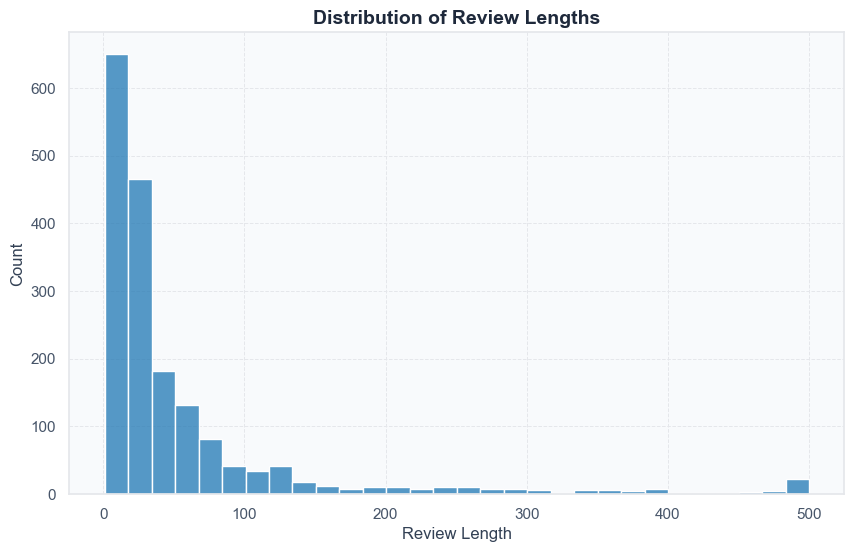

In [ ]:
df['length'] = df['content'].apply(len)

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='length', bins=30)
plt.title('Distribution of Review Lengths')
plt.xlabel('Review Length')
plt.ylabel('Count')
plt.show()

Dari grafik di atas, ternyata terdapat beberapa data yang memiliki karakter sangat panjang dibanding yang lainnya, yaitu sekitar 500 karakter. Selain itu, data dengan karakter kecil seperti 1-2 karakter juga tergolong sangat banyak, mari kita lihat apa saja data-data tersebut

In [1552]:
df['length'].value_counts().sort_index(ascending=False).head(10)

length
500    3
499    4
498    3
497    1
495    1
494    2
492    2
489    2
488    2
487    1
Name: count, dtype: int64

In [1553]:
df['length'].value_counts().sort_index(ascending=True).head(10)

length
1     10
2     15
3     25
4     50
5     21
6     29
7     28
8     40
9     72
10    35
Name: count, dtype: int64

In [1554]:
df[df['length'] == 1]

,content,score,game,length
97,👍,5,PUBG Mobile,1
180,😠,1,PUBG Mobile,1
225,😍,5,PUBG Mobile,1
265,😍,4,PUBG Mobile,1
389,😱,3,PUBG Mobile,1
500,🥰,5,PUBG Mobile,1
548,😘,5,PUBG Mobile,1
1415,💥,5,Free Fire,1
1749,🙂,5,Free Fire,1
1983,👍,5,Free Fire,1


In [1555]:
df[df['length'] == 2]

,content,score,game,length
93,ok,5,PUBG Mobile,2
196,ok,4,PUBG Mobile,2
339,👍😊,5,PUBG Mobile,2
531,❣️,5,PUBG Mobile,2
578,👌🏻,5,PUBG Mobile,2
636,✅💯,5,PUBG Mobile,2
648,🥰😍,5,PUBG Mobile,2
670,👍👍,5,PUBG Mobile,2
824,🤗🍁,5,PUBG Mobile,2
837,🫡🫡,5,PUBG Mobile,2


Ternyata contoh-contoh data dengan karakter sedikit cenderung hanya berisi emoji saja, ini merupakan sebuah noise yang nanti perlu dihandle.

In [1556]:
df.sort_values(by='length', ascending=False).head(10)

,content,score,game,length
1509,What about hackers(dogs) & panels in this game...,1,Free Fire,500
1449,Free Fire is one of the most popular mobile ba...,1,Free Fire,500
1545,Gamenya burik!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,5,Free Fire,500
177,PUBG: Battlegrounds is one of the most popular...,5,PUBG Mobile,499
579,"DEAR PUBG Mobile Support Team,I am writing to ...",5,PUBG Mobile,499
1704,BGMI is better than this game because at least...,1,Free Fire,499
1334,මම ඔයත් එක්ක ඉන්න මම හෙට සිට ඇති ඇති මම දැන් ය...,5,Free Fire,499
1381,saya suka main ff sebab abang saya ajar saya s...,5,Free Fire,498
618,Honestly speaking pubg mobile is a good game b...,1,PUBG Mobile,498
629,"I can't say pubg doesn't deserve a five star, ...",5,PUBG Mobile,498


Contoh karakter banyak juga terlihat terdapat beberapa noise, seperti perulangan tanda seru yang sangat banyak '!!!!!!!!'. Pada dataset, juga terdapat noise yaitu bahasa-bahasa asing yang bukan tergolong bahasa inggris, contohnya seperti Bahasa Indonesia.

#### B.4.2. Word Count Distribution

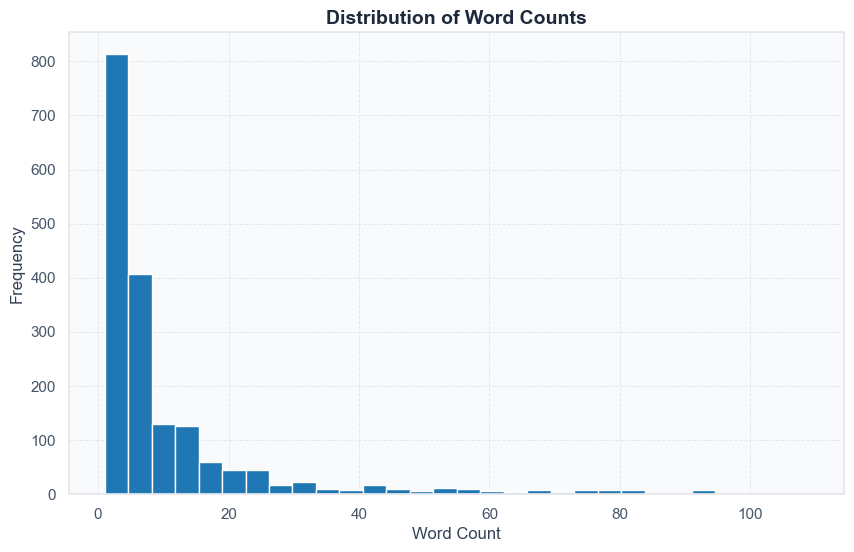

In [1557]:
df['word_count'] = df['content'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 6))
plt.hist(df['word_count'], bins=30)
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.title('Distribution of Word Counts')
plt.show()

Di bagian ini, saya bertujuan untuk melihat berapa kata yang terdapat dalam satu data. Dapat terlihat bahwa rata-rata kata berada pada jumlah 0-20 kata saja. Namun terdapat juga beberapa kata yang berada di atas 60 kata. 

In [1558]:
df['word_count'].value_counts().sort_index(ascending=False).head(10)

word_count
109    1
105    2
101    1
98     1
96     2
94     2
93     2
92     2
91     2
89     1
Name: count, dtype: int64

In [1559]:
df['word_count'].value_counts().sort_index(ascending=True).head(10)

word_count
1     165
2     196
3     246
4     206
5     146
6     104
7      87
8      70
9      53
10     38
Name: count, dtype: int64

In [1560]:
df[df['word_count'] == 1]

,content,score,game,length,word_count
3,gut,5,PUBG Mobile,3,1
10,Nice,5,PUBG Mobile,4,1
22,wow,5,PUBG Mobile,3,1
30,good,5,PUBG Mobile,4,1
31,thankio,5,PUBG Mobile,7,1
...,...,...,...,...,...
1943,ហ្កេមចាប់តុកក្តា,5,Free Fire,16,1
1964,top,4,Free Fire,3,1
1970,pro,5,Free Fire,3,1
1981,cool,4,Free Fire,4,1


In [1561]:
df[df['word_count'] == 2]

,content,score,game,length,word_count
4,solo play,5,PUBG Mobile,9,2
7,excellent game,5,PUBG Mobile,14,2
16,good game,5,PUBG Mobile,9,2
21,nice 👍,4,PUBG Mobile,6,2
27,love 💕,5,PUBG Mobile,6,2
...,...,...,...,...,...
1947,بسسب الغش,1,Free Fire,9,2
1975,I likeeeeee!!!!!,5,Free Fire,16,2
1988,Wow 😲😲😲,5,Free Fire,7,2
1992,the bast,5,Free Fire,8,2


Contoh kata dengan jumlah 1-2 biasanya hanya berisi 'good', 'nice', 'good game'. Kata-kata tersebut cenderung mencerminkan raating tinggi.

In [1562]:
df.sort_values(by='word_count', ascending=False).head(10)

,content,score,game,length,word_count
1334,මම ඔයත් එක්ක ඉන්න මම හෙට සිට ඇති ඇති මම දැන් ය...,5,Free Fire,499,109
928,update these game is to bad for low end device...,1,PUBG Mobile,476,105
1573,🥰*g ap gg ap mujhe ko ap se mohbat h be had be...,5,Free Fire,479,105
387,good game but there is some issues like fps dr...,5,PUBG Mobile,494,101
96,"“Hello, I have been playing PUBG for 6 or 7 ye...",1,PUBG Mobile,494,98
618,Honestly speaking pubg mobile is a good game b...,1,PUBG Mobile,498,96
1114,i want to make a complain concerning a br rank...,4,Free Fire,492,96
1381,saya suka main ff sebab abang saya ajar saya s...,5,Free Fire,498,94
1704,BGMI is better than this game because at least...,1,Free Fire,499,94
1338,Since there's no feedback website let me say i...,5,Free Fire,488,93


Data di atas merupakan contoh data yang memiliki jumlah kata yang panjang. Berdasarkan analisis saya, terdapat beberapa data yang bahasanya kurang jelas. Namun terdapat juga data yang mungkin dapat menyimpan informasi penting mengenai game yang sedang direview. Sehingga pada step ini saya memutuskan untuk tidak melakukan filtering data berdasarkan word count. Karena bisa saja terdapat informasi penting yang berada pada data tersebut

#### B.4.3. Wordcloud

In [1563]:
from wordcloud import WordCloud

Selanjutnya saya melakukan analisis menggunakan WordCloud, yaitu suatu library/function untuk memvisualisasikan kata apa saja yang paling sering muncul. Di bagian ini saya membagi setiap WordCloud berdasarkan kelas mereka. Tujuannya untuk menganalisis karakteristik kata pada setiap kelas dan menganalisis noise pada data.

In [1564]:
def generate_wordcloud(text, title):
    wc = WordCloud(width=1000, height=500, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(title, fontsize=20)
    plt.axis('off')
    plt.show()

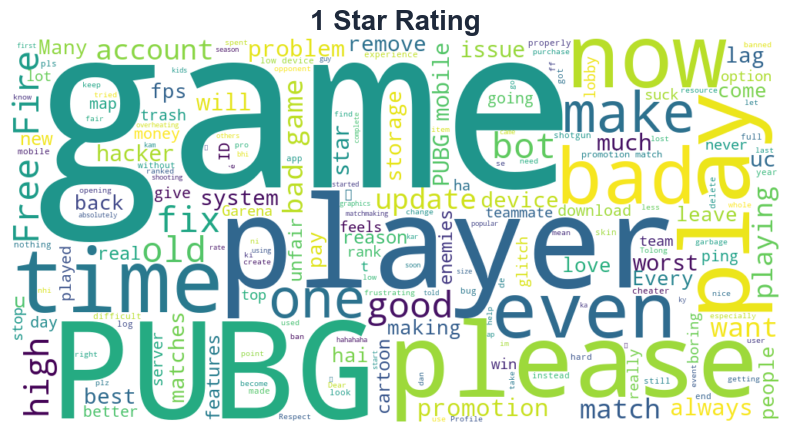

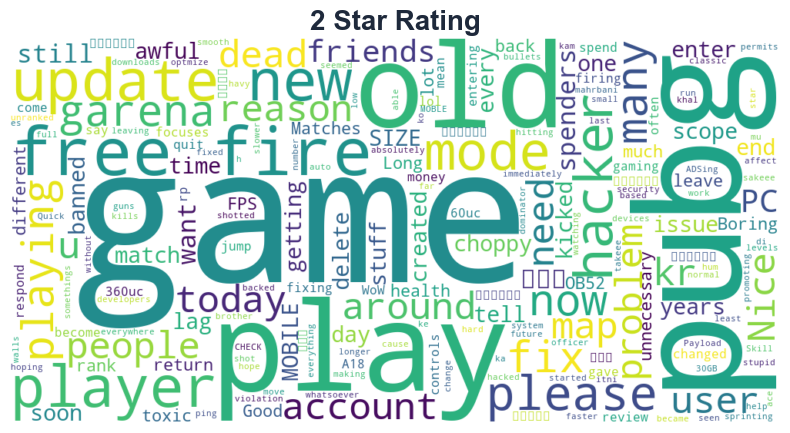

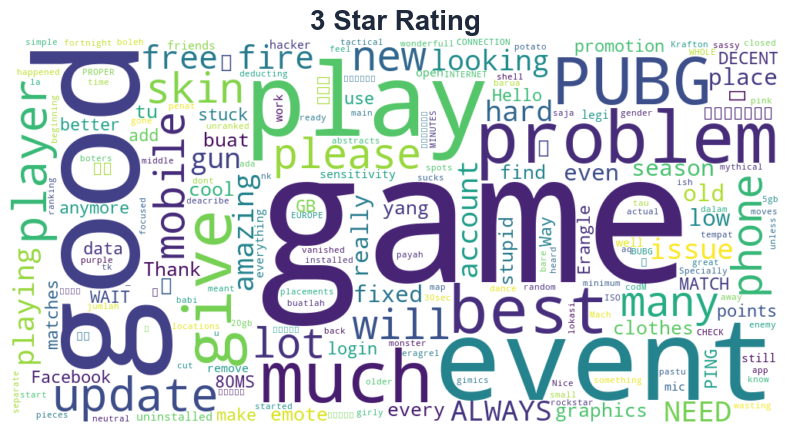

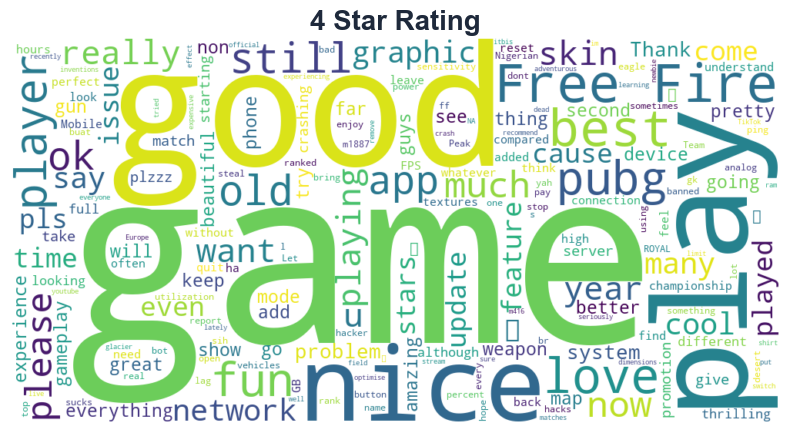

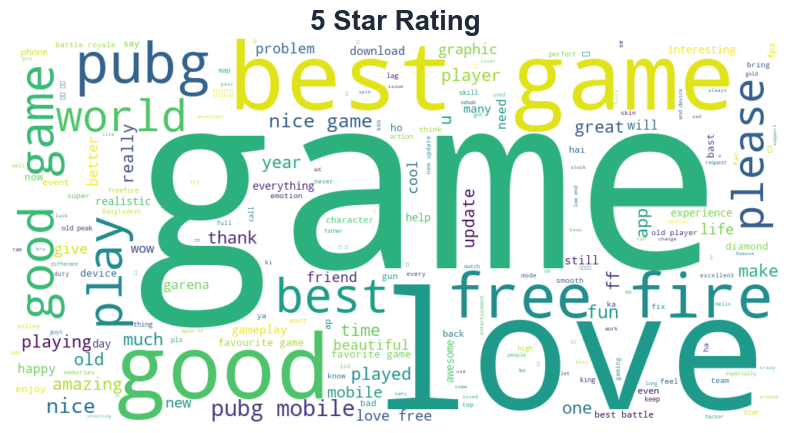

In [1565]:
ratings = [1, 2, 3, 4, 5]

for r in ratings:
    generate_wordcloud(df[df['score'] == r]['content'].str.cat(sep=' '), f"{r} Star Rating")

Berdasarkan hasil di atas dan melakukan analisis, saya mendapatkan hasil sebagai berikut:
1. Setiap kelas memiliki kata dengan frekuensi tinggi yang sama, yaitu 'game'. Kata 'game' tidak menggambarkan suatu karakteristik dari kelas tersebut sehingga saya pertimbangkan untuk nanti dibersihkan
2. Pada kelas rating 3-5, kata yang cukup besar frekuensinya adalah 'good' dan 'nice'. Dengan melihat hal ini, saya memprediksi bahwa model akan cukup kesulitan membedakan ketiga kelas tersebut (3,4,5) dikarenakan karakteristik kata yang mirip. 
3. Pada kelas 1-2, terdapat beberapa kata yang menggambarkan kelas tersebut (kelas rating rendah), contohnya seperti 'bad' dan 'fix'. Namun frekuensi kata tersebut tergolong rendah, dan tertutup dengan kata lain yang kurang menggambarkan kelas rating rendah. Sehingga, menurut prediksi saya, model dapat kesulitan untuk memprediksi dan membedakan kelas ini dengan kelas lainnya.

#### B.4.4. Top Word Frequency

In [1566]:
from sklearn.feature_extraction.text import CountVectorizer

def word_frequency(df, label):
    subset = df[df['score'] == label]

    vectorizer = CountVectorizer(stop_words='english')
    X = vectorizer.fit_transform(subset['content'])

    freq = X.sum(axis=0).A1
    vocab = vectorizer.get_feature_names_out()

    freq_df = pd.DataFrame({'word': vocab, 'frequency': freq})
    freq_df = freq_df.sort_values(by='frequency', ascending=False)

    return freq_df

Untuk melihat dengan lebih jelas, frekuensi kata dapat dilihat dengan menggunakan grafik di bawah ini.

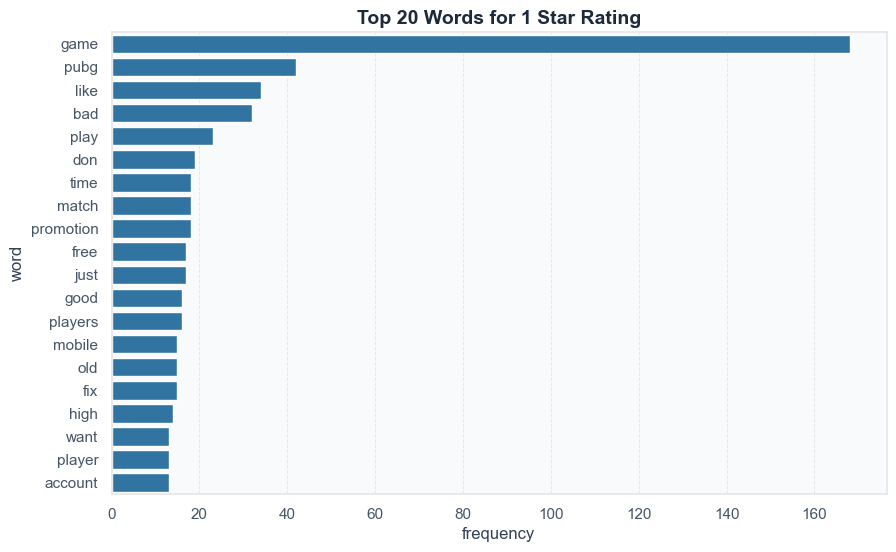

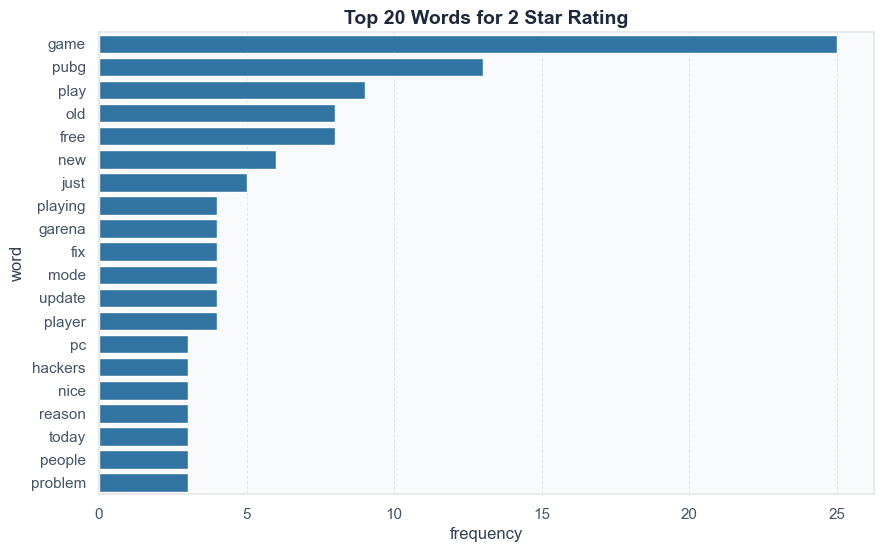

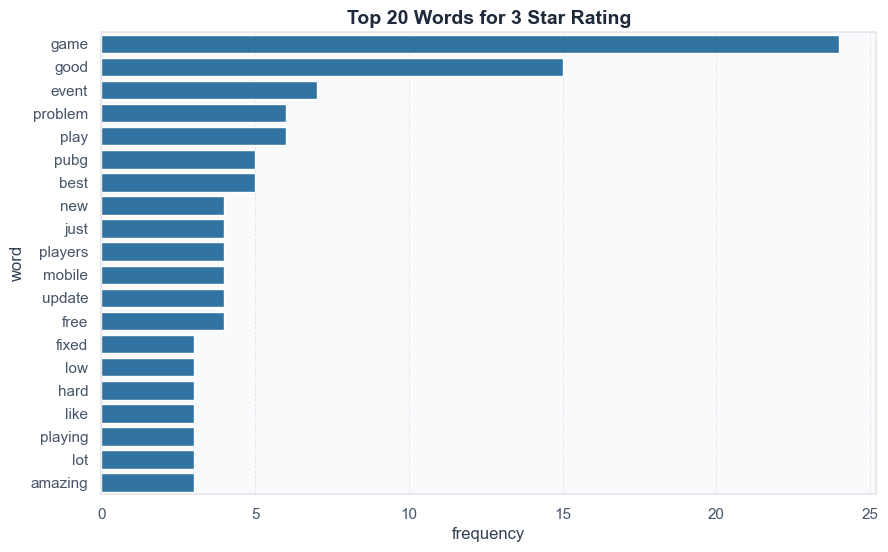

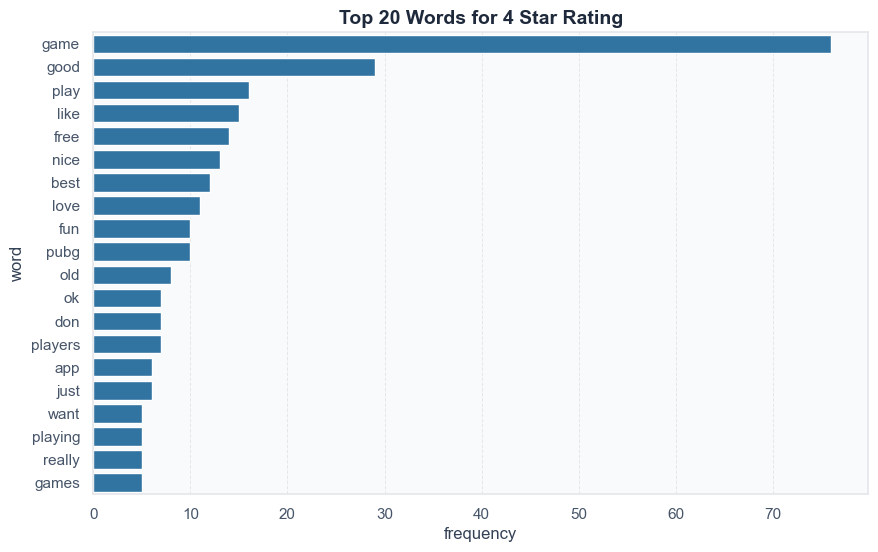

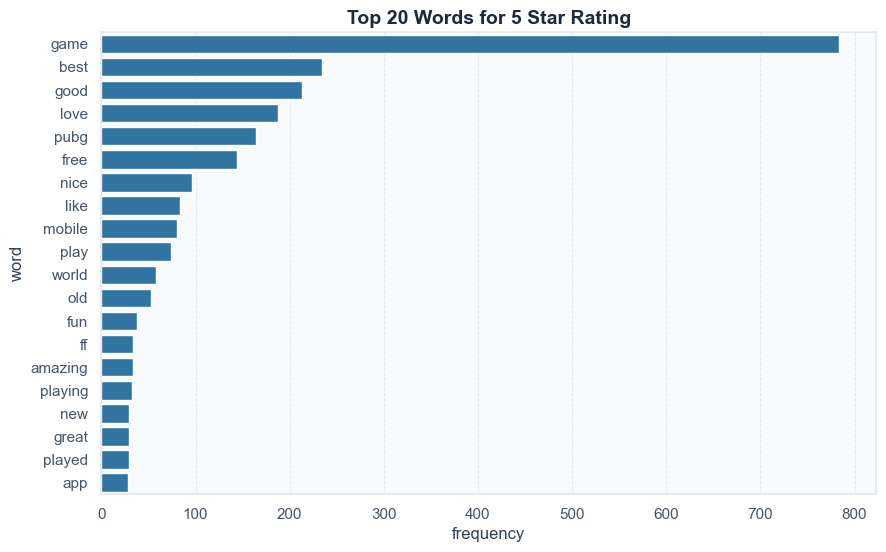

In [1567]:
ratings = [1, 2, 3, 4, 5]

for r in ratings:
    freq_df = word_frequency(df, r)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=freq_df.head(20), x='frequency', y='word')
    plt.title(f'Top 20 Words for {r} Star Rating')
    plt.show()

#### B.4.5. Label Distribution

Selain melihat karakteristik data terutama fitur yang dimiliki. Melihat distribusi kelas juga sangatlah penting, karena distribusi kelas dapat mempengaruhi banyak aspek ketika melakukan pemodelan klasifikasi

In [1568]:
df['score'].value_counts()

score
5    1354
1     246
4     112
3      53
2      36
Name: count, dtype: int64

<Axes: ylabel='count'>

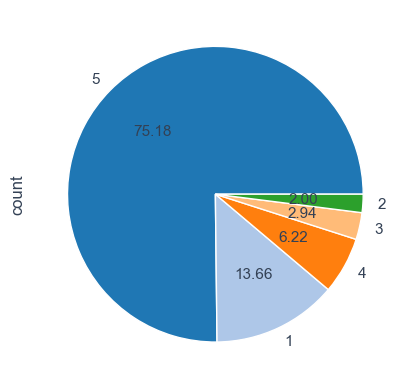

In [1569]:
df['score'].value_counts().plot.pie(autopct='%.2f')

Berdasarkan data dan grafik di atas, terlihat dengan sangat jelas bahwa dataset yang saya miliki memiliki kelas yang sangat-sangat imbalance. Data terbanyak ada pada kelas 5 dan disusul oleh kelas 1. Hal ini cukup umum terjadi pada dataset review, dikarenakan pengguna akan lebih cenderung memberikan nilai 5 ketika menyukai, dan langsung memberikan 1 ketika tidak menyukai app tersebut.

==========================================================================================================================================================================================

## C. Preprocessing

Anda melihat bahwa data ini tidak bisa langsung digunakan dalam membangun
model prediksi rating, maka anda melakukan preprocessing data hingga mendapatkan bentuk token paling efektif
yang sesuai kaidah tata bahasa dan sebisa mungkin makna kata tersebut tidak berubah apalagi kelas katanya.

Setelah melihat hasil EDA pada bagian sebelumnya, memang ditemukan bahwa data sangat tidak layak untuk langsung digunakan dalam training. Sehingga data perlu diolah terlebih dahulu dan ditingkatkan kualitasnya agar model klasifikasi dapat menghasilkan performa yang optimal

### C.1. Text Cleaning

In [1570]:
import re

Langkah pertama yang saya lakukan adalah melakukan text cleaning atau membersihkan teks. Karakter yang paling penting untukd dibersihkan contohnya adalah emoji, karakter spam berulang, URL, spasi berlebih, dan lain-lain.

In [1571]:
def text_cleaning(text):
    text = text.lower() # lowercase
    text = re.sub(r'[\n\r\t]', ' ', text) # delete newline atau tab
    text = text.replace("`", "'") # ganti petik, jadi petik yang biasa
    text = re.sub(r'http\S+|www\S+', '', text) # hapus jika ada URL
    text = re.sub(r'@\w+|#\w+', '', text) # hapus mention or hastag
    text = re.sub(r'\d+', '', text) # hapus angka
    text = re.sub(r'(.)\1{2,}', r'\1\1', text) # hapus huruf banyak berulang
    text =re.sub(r"[^a-z\s']", ' ', text) # hapus karakter selain alfabet dan petik
    text = re.sub(r'\s+', ' ', text).strip() # rapihin spasi berlebih
    return text

In [1572]:
df = df.copy()
df['content'] = df['content'].apply(text_cleaning)
df.head()

,content,score,game,length,word_count
0,the game is so bad,5,PUBG Mobile,18,5
1,i delete my game update ke waja sa,5,PUBG Mobile,34,8
2,best game,5,PUBG Mobile,12,3
3,gut,5,PUBG Mobile,3,1
4,solo play,5,PUBG Mobile,9,2


Hasil dari text cleaning adalah teks yang seluruhnya menjadi huruf kecil, bersih dari emoji, dan hanya berisikan karakter alfabet saja. Namun saya masih menyisakan tanda baca petik ('), karena biasanya menandakan singkatan seperti 'don't'.

### C.2. Handle Abbreviation

Kemudian langlah selanjutnya adalah mengatasi singkatan-singkatan tersebut agar kembali menjadi bentuk bakunya. Berikut adalah dictionary yang sudah dibuat untuk mengubah kata singkatn kembali menjadi bentuk baku.

In [1573]:
dictionary = {
    "ain't": "is not",
    "aren't": "are not",
    "can't": "cannot",
    "couldn't": "could not",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hasn't": "has not",
    "haven't": "have not",
    "he'll": "he will",
    "he's": "he is",
    "i'll": "i will",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it's": "it is",
    "let's": "let us",
    "she'll": "she will",
    "she's": "she is",
    "shouldn't": "should not",
    "that's": "that is",
    "there's": "there is",
    "they're": "they are",
    "they've": "they have",
    "we're": "we are",
    "we'll": "we will",
    "weren't": "were not",
    "what's": "what is",
    "who's": "who is",
    "won't": "will not",
    "wouldn't": "would not",
    "you're": "you are",
    "you've": "you have"
}

In [1574]:
def handle_abbreviations(text):
    text = text.split()
    text = [dictionary[w] if w in dictionary else w for w in text]
    return ' '.join(text)

In [1575]:
df['content'] = df['content'].apply(handle_abbreviations)

In [1576]:
df.head()

,content,score,game,length,word_count
0,the game is so bad,5,PUBG Mobile,18,5
1,i delete my game update ke waja sa,5,PUBG Mobile,34,8
2,best game,5,PUBG Mobile,12,3
3,gut,5,PUBG Mobile,3,1
4,solo play,5,PUBG Mobile,9,2


### C.3. Data Splitting

In [1577]:
from sklearn.model_selection import train_test_split

Setelah melakukan text cleaning dan handle abbreviations, selanjutnya saya melakukan splitting data. Hal ini saya lakukan sebelum melakukan preprocessing yang lain, tujuannya adalah mencegah adanya data leaking dan inconsistent data. Walau beberapa proses setelah ini tidak menyebabkan data leaking dikarenakan merupakan rule based preprocessing. Namun akan lebih baik jika splitting dilakukan terlebih dahulu agar mencegah data leak dan menjaga integritas data.

In [1578]:
X = df[['content']]
y = df['score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### C.4. Tokenization

In [1579]:
from nltk.tokenize import word_tokenize

Setelah melakukan splitting data, berikutnya adalah melakukan tokenisasi tujuannya adalah memecah kalimat menjadi kata-kata tunggal atau disebut dengan token. Tujuan tokenisasi adalah dikarenakan model akan memproses data dalam bentuk satuan token bukan dalam bentuk kalimat.

In [1580]:
X_train['tokens'] = [word_tokenize(text) for text in X_train['content']]
X_test['tokens'] = [word_tokenize(text) for text in X_test['content']]

In [1581]:
X_train.head()

,content,tokens
1721,free fire is the best baber,"[free, fire, is, the, best, baber]"
1713,good gamd network issues,"[good, gamd, network, issues]"
1424,nice and easy gameplay it is my best game,"[nice, and, easy, gameplay, it, is, my, best, ..."
605,this is very beautiful game,"[this, is, very, beautiful, game]"
182,good but shake it off u cants compete with fre...,"[good, but, shake, it, off, u, cants, compete,..."


In [1582]:
max_len = X_train['tokens'].apply(len).max()
max_len

np.int64(102)

In [1583]:
vocab_size = len(set(word for tokens in X_train['tokens'] for word in tokens))
vocab_size

2514

In [1584]:
X_train.head()

,content,tokens
1721,free fire is the best baber,"[free, fire, is, the, best, baber]"
1713,good gamd network issues,"[good, gamd, network, issues]"
1424,nice and easy gameplay it is my best game,"[nice, and, easy, gameplay, it, is, my, best, ..."
605,this is very beautiful game,"[this, is, very, beautiful, game]"
182,good but shake it off u cants compete with fre...,"[good, but, shake, it, off, u, cants, compete,..."


### C.5. Stopword Removal

In [1585]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\johan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\johan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\johan\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Kemudian preprocessing berikutnya adalah Stopword Removal, atau menghilangkan kata-kata umum atau konjungsi atau kata yang tidak memiliki makna apapun pada kelas. Tujuannya untuk mengurangi vocab yang tidak perlu pada dataset.

In [1586]:
stopwords_additional = ['u', 'im', 'ur', 'dont', 'doin', 'ure', '4', '2', 'ive', 's', 't', 'll', 'd', 've', 'm']
non_characteristic_words = ['game', 'pubg', 'garena', 'fire', 'ff']

Pada bagian ini, saya juga menambahkan beberapa kata tambahan yang tergolong sebagai stopword. Saya memberi nama 'non_characteristic_words', artinya adalah kata-kata yang muncul pada setiap kelas namun tidak memberikan makna atau sentimen apapun pada kelas tersebut.

In [1587]:
stopwords = set(stopwords.words('english'))
stopwords.discard('no')
stopwords.discard('not')

Di sini saya exclude atau tidak memasukkan 'not' dan 'no' pada stopwords, dikarenakan kata tersebut dapat memberikan makna seperti 'not good' atau 'not bad'.

In [1588]:
stop_words_final = stopwords.union(stopwords_additional, non_characteristic_words)

In [1589]:
def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in stop_words_final])

In [1590]:
X_train['content'] = X_train['content'].apply(remove_stopwords)
X_test['content'] = X_test['content'].apply(remove_stopwords)

In [1591]:
X_train.head()

,content,tokens
1721,free best baber,"[free, fire, is, the, best, baber]"
1713,good gamd network issues,"[good, gamd, network, issues]"
1424,nice easy gameplay best,"[nice, and, easy, gameplay, it, is, my, best, ..."
605,beautiful,"[this, is, very, beautiful, game]"
182,good shake cants compete free guys thing like ...,"[good, but, shake, it, off, u, cants, compete,..."


In [1592]:
X_test.head()

,content,tokens
1056,free lover,"[free, fire, lover]"
1935,love free,"[my, love, free, fire]"
847,love mobile,"[i, love, you, pubg, mobile]"
169,,[]
1381,saya suka main sebab abang saya ajar saya saya...,"[saya, suka, main, ff, sebab, abang, saya, aja..."


Pada proses ini, dapat dilihat bahwa saya hanya melakukan stopword removal pada kolom 'content'. Hal ini dikarenakan kolom 'tokens' akan dijadikan data yang menggunakan representasi Word2Vec, di mana Word2Vec dapat belajar mengenai konteks pada kalimat. Stopword yang dihilangkan bisa saja memberikan relasi antar kata dan membantu Word2Vec dalam menangkap konteks pada kalimat.

### C.6. Lemmatization

In [1593]:
from nltk import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

Selanjutnya adalah melakukan lematisasi, tujuannya adalah untuk mengembalikan kata menjadi bentuk kata aslinya atau kata bakunya. Proses ini saya lakukan pada 2 kolom tersebut, yaitu 'content' dan 'tokens' dengan setiap data train dan test diperlakukan dengan sama. Dengan melakukan lematisasi, saya dapat mengurangi ukuran dimensi dataset sehingga model dapat mempelajari kata dengan terfokus daripada mempelajari beberapa kata dengan makna yang sama.

In [1594]:
def lemmatize(text):
    return ' '.join([lemmatizer.lemmatize(word) for word in text.split()])

In [1595]:
X_train['content'] = X_train['content'].apply(lemmatize)
X_test['content'] = X_test['content'].apply(lemmatize)

In [1596]:
def lemmatize_tokens(token_list):
    return [lemmatizer.lemmatize(word) for word in token_list]

In [1597]:
X_train['tokens'] = X_train['tokens'].apply(lemmatize_tokens)
X_test['tokens'] = X_test['tokens'].apply(lemmatize_tokens)

In [1598]:
X_train.head()

,content,tokens
1721,free best baber,"[free, fire, is, the, best, baber]"
1713,good gamd network issue,"[good, gamd, network, issue]"
1424,nice easy gameplay best,"[nice, and, easy, gameplay, it, is, my, best, ..."
605,beautiful,"[this, is, very, beautiful, game]"
182,good shake cant compete free guy thing like ma...,"[good, but, shake, it, off, u, cant, compete, ..."


### C.7. Visualization After Cleaning

#### C.7.1. Check Data 

In [1599]:
df[df['content'] == '']

,content,score,game,length,word_count
47,,5,PUBG Mobile,17,3
84,,5,PUBG Mobile,3,1
97,,5,PUBG Mobile,1,1
99,,5,PUBG Mobile,96,20
109,,5,PUBG Mobile,65,15
...,...,...,...,...,...
1932,,5,Free Fire,33,7
1943,,5,Free Fire,16,1
1947,,1,Free Fire,9,2
1949,,1,Free Fire,35,7


In [1600]:
df = df[df['content'] != '']

In [1601]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1669 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   content     1669 non-null   object
 1   score       1669 non-null   int64 
 2   game        1669 non-null   object
 3   length      1669 non-null   int64 
 4   word_count  1669 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 78.2+ KB


#### C.7.2. Length Distribution

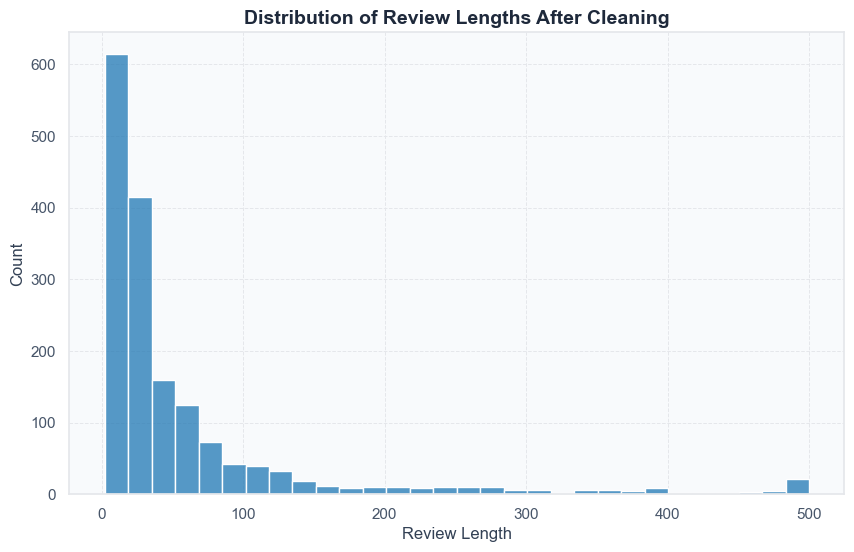

In [1602]:
plt.figure(figsize=(10, 6))
sns.histplot(df['length'], bins=30)
plt.title('Distribution of Review Lengths After Cleaning')
plt.xlabel('Review Length')
plt.show()

#### C.7.3. Word Count Distribution

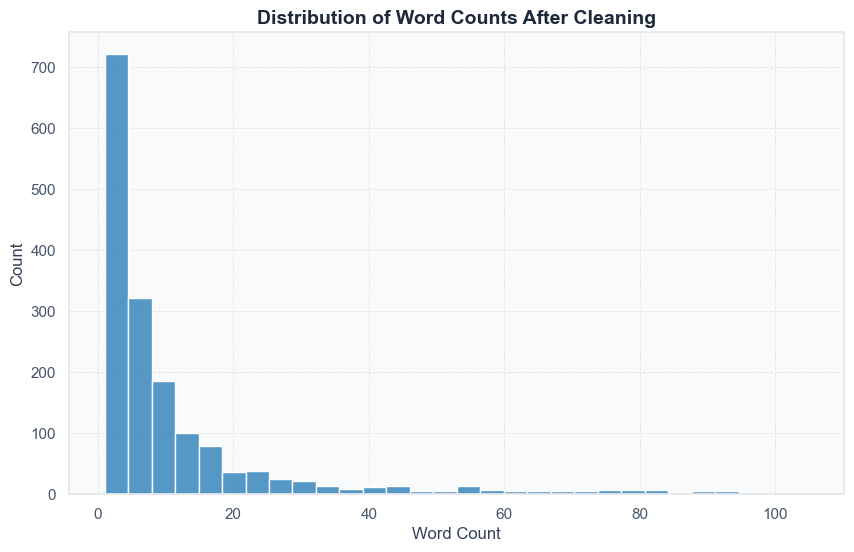

In [1603]:
plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], bins=30)
plt.title('Distribution of Word Counts After Cleaning')
plt.xlabel('Word Count')
plt.show()

#### C.7.4. WordCloud After Cleaning

Setelah melakukan preprocessing dan membersihkan data, saya melakukan recheck kembali menggunakan WordCloud untuk melihat apakah setelah melakukan pembersihan data, karakteristik kata pada setiap kelas akan lebih terlihat. Saya juga ingin melihat apakah kualitas data pada setiap kelas meningkat setelah preprocessing dan cleaning data.

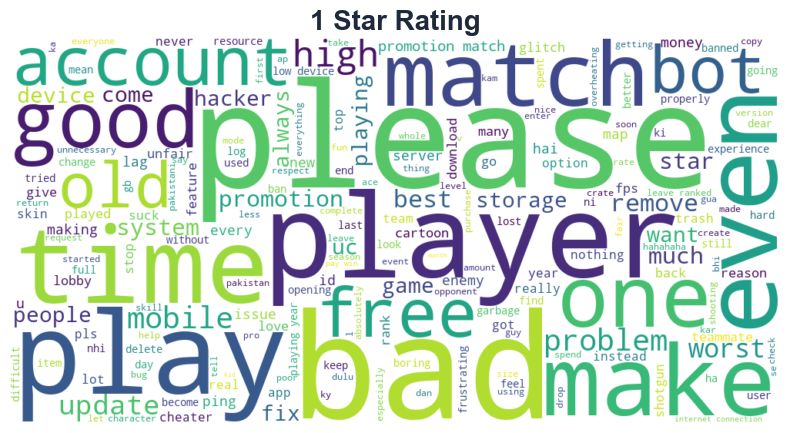

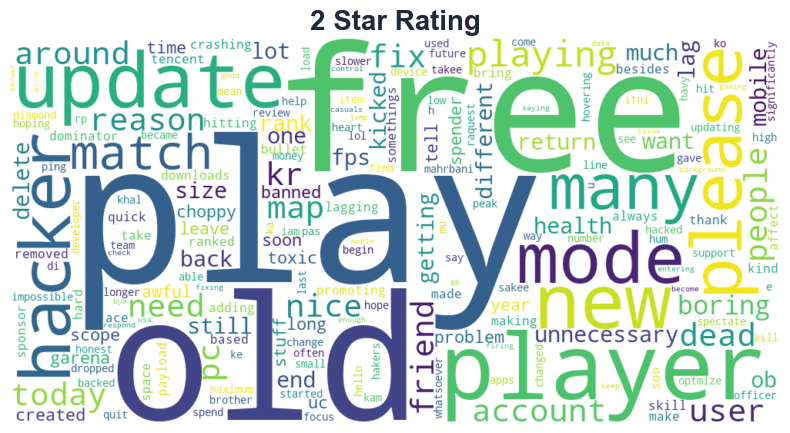

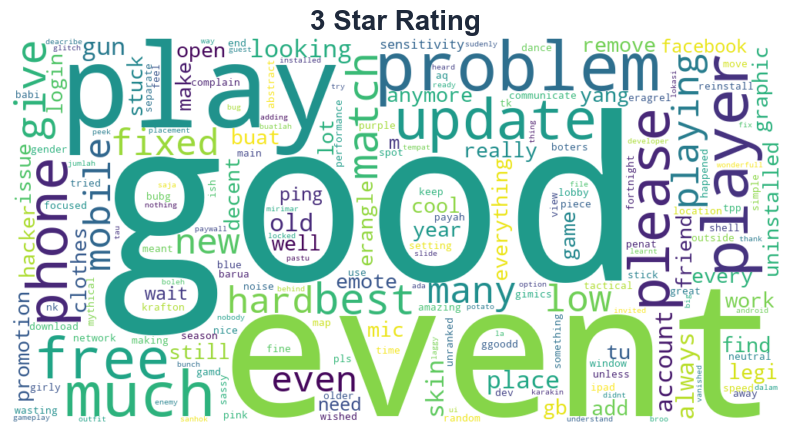

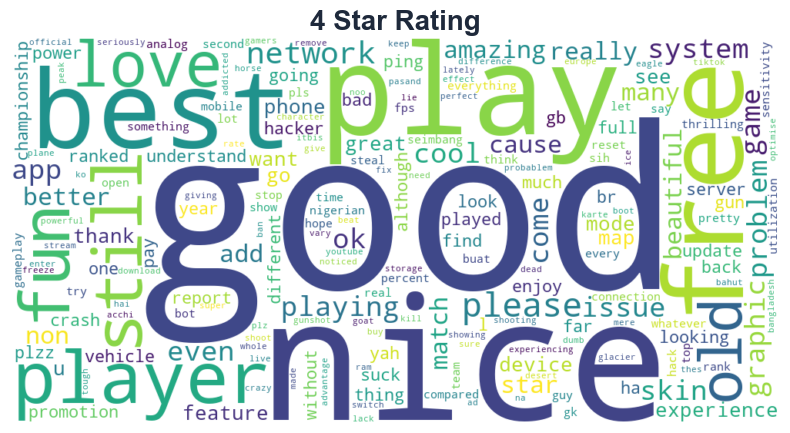

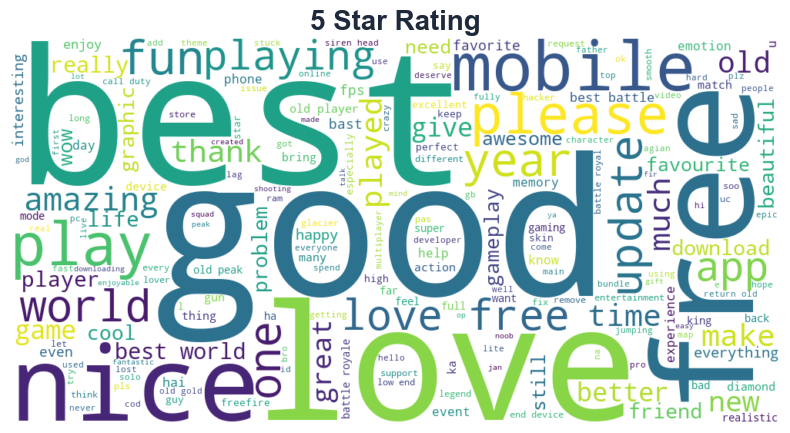

In [1604]:
for r in ratings:
    generate_wordcloud(X_train[y_train == r]['content'].str.cat(sep=' '), f"{r} Star Rating")

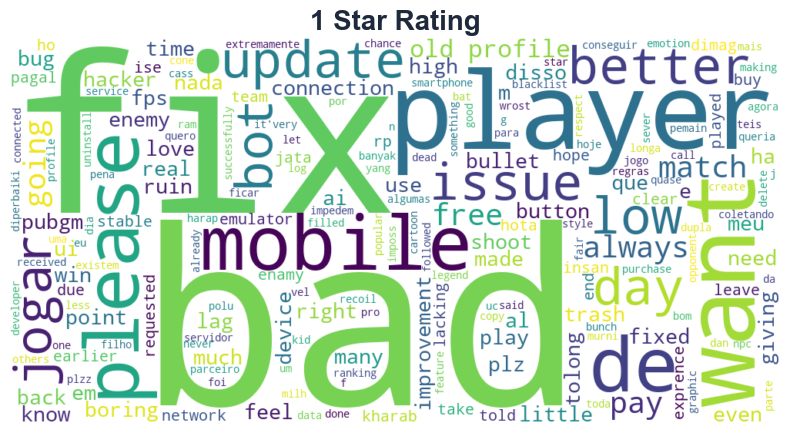

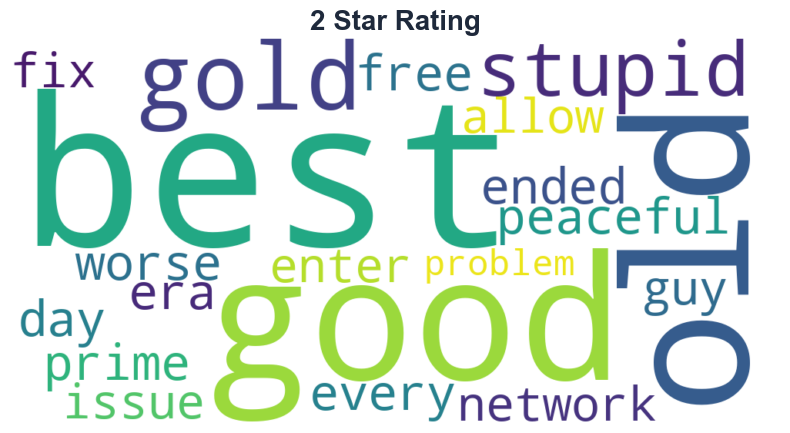

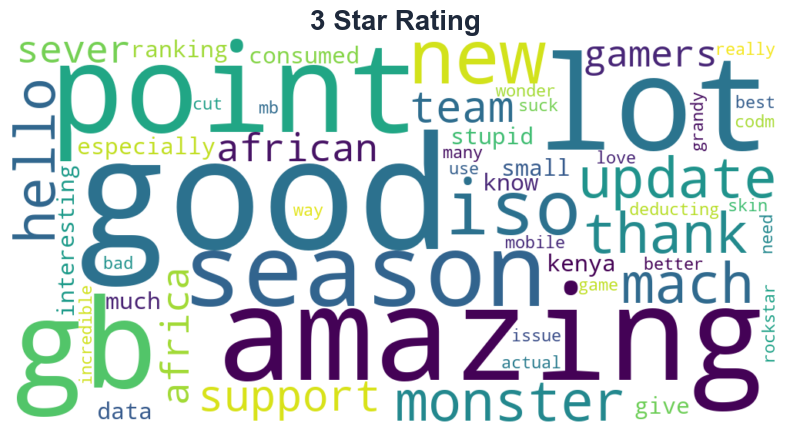

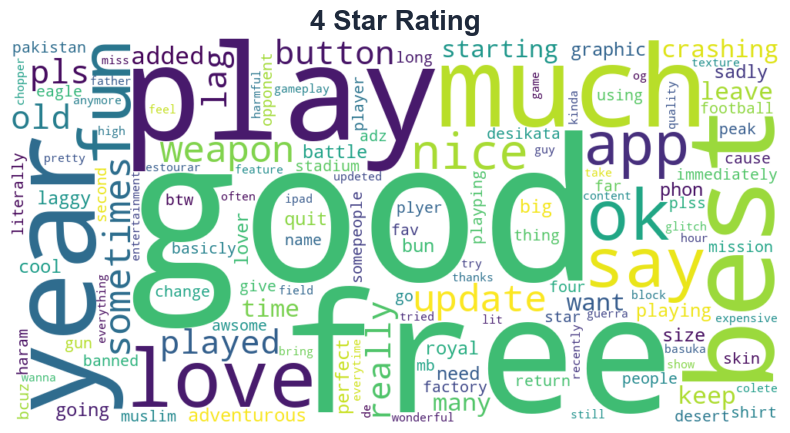

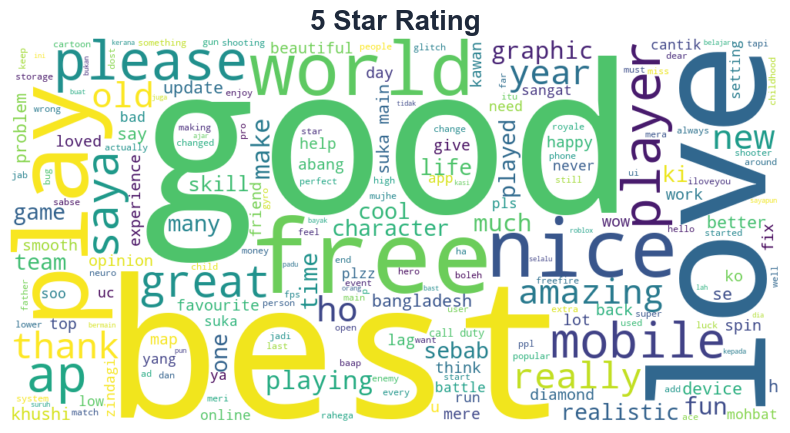

In [1605]:
for r in ratings:
    generate_wordcloud(X_test[y_test == r]['content'].str.cat(sep=' '), f"{r} Star Rating")

Setelah melakukan pembersihan dan cleaning, WordClout memperlihatkan peningkatan yang cukup baik, yaitu kelas-kelas mulai menunjukkan karakteristik kata yang sesuai dengan kelas rating mereka. Walaupun pada kelas kecil seperti 1-2 masih sulit untuk menonjolkan kata dominan dari kelas tersebut.

==========================================================================================================================================================================================

## D. Text Representation

Anda memutuskan akan menggunakan machine learning unutk model prediksi,
namun sebelum itu anda perlu merepresentasikan data teks ini kedalam bentuk vektor yang dapat diterima oleh
machine learning sebagai input, maka anda menerapkan 2 bentuk metode text representation yaitu, metode yang
nilai vectornya merepresentasikan seberapa penting kata tersebut dalam suatu data sample, dan metode yang
vectornya direpresentasikan oleh kata disekitarnya yang ditraining dengan model ANN dengan input kata dan target
kata yang ada disekitarnya. Anda akan mencoba kedua metode text representation ini sebagai input yang kemudian
akan dibandingkan performance prediksinya

Berdasarkan soal di atas, maka metode text representation yang paling cocok dan memenuhi kriteria adalah TFIDF dan Word2Vec. Berikut ini adalah proses melakukan representasi teks menggunakan 2 metode/pendekatan tersebut.

### D.1. TF-IDF

In [1606]:
from sklearn.feature_extraction.text import TfidfVectorizer

TFIDF atau Term Frequency - Inverse Document Frequency adalah metode representasi teks dengan merubah token menjadi angka berdasarkan seberapa sering kata tersebut muncul di satu kalimat. Namun TFIDF juga memberikan penalti ketika kata tersebut terlalu sering muncul pada seluruh dataset

!['tfidf'](images/tfidf.png)

#### D.1.1. Without Editing Parameter

In [1607]:
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train['content'])
X_test_tfidf = vectorizer.transform(X_test['content'])

Yang dimasukkan ke TFIDF adalah 'content' yang masih berisi kalimat, dikarenakan pada proses TFIDF sendiri, sudah include dengan proses tokenisasi bawaan dari TFIDF Vectorizer.

In [1608]:
TFIDF = pd.DataFrame(X_train_tfidf.toarray(), columns=vectorizer.get_feature_names_out())
TFIDF.head()

,aaj,aao,ab,abandon,abedatse,abi,able,abnormal,absolute,absolutely,...,yrr,yt,yy,zada,zaroori,zaya,zero,zindagi,zombie,zone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Pada proses pertama, saya mencoba untuk menggunakan standard TFIDF tanpa edit parameternya. Artinya seluruh kata yang ada di 'content' akan ditokenisasi dan dihitung nilai vectornya dengan TFIDF. Namun, setelah saya analisis, ternyata vocab yang terbentu sangat besar, dan banyak berisi kata-kata seperti 'aaj', 'aao', yang tidak memiliki makna dan merupakan noise. Sehingga saya memutuskan untuk edit parameternya.

#### D.1.2. With Edit Parameter (min_df = 2)

In [1609]:
vectorizer_new = TfidfVectorizer(min_df=2, max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer_new.fit_transform(X_train['content'])
X_test_tfidf = vectorizer_new.transform(X_test['content'])

Pada proses kedua ini, saya memutuskan untuk melakukan edit pada 2 parameter, yaitu min_df dan ngram_range. 
1. min_df = 2 --> artinya hanya memasukkan kata yang minimal muncul 2 kali pada dataset. Ini mencegah kata-kata typo atau spam masuk ke dalam fitur
2. ngram_range=(1,2) --> artinya menggunakan unigram + bigram, dimana unigram menangkap setiap kata secara individual, sedangkan bigram menangkap 2 kata sekaligus, tujuannya adalah menangkap relasi antar kata 

In [1610]:
TFIDF_new = pd.DataFrame(X_train_tfidf.toarray(), columns=vectorizer_new.get_feature_names_out())
TFIDF_new.head()

,ab,absolute,absolute cinema,absolutely,acchi,acchi hai,account,account hacked,account not,ace,...,yang,year,year ago,year old,year since,year still,yet,youtube,zero,zero star
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### D.2. Word2Vec - CBOW

In [1611]:
import gensim
from gensim.models import Word2Vec
import numpy as np

Word2Vec merupakan metode text representation yang tersedia dalam library gensim. Word2Vec dapat mempelajari makna dan konteks dari sebuah kata dalam kalimat. Tujuan utamanya adalah mempelajari kata yang memiliki konteks mirip, sehingga nilai vektornya juga mirip.

!['cbow'](images/cbow.png)

Model CBOW maupun Skipgram akan menerima input berupa one hot encoding dari sebuah kata, kemudian dihitung dan diproyeksikan ke dalam hidden layer. Nilai vektor kata tersebut diambil dari bobot pada hidden layer yang terus diupdate selama proses training. Hidden layer sebagai feature extractor ini yang menyimpan informasi konteks dan semantik dari kata yang sedang dipelajari.

#### D.2.1. For Machine Learning

In [1612]:
w2v_model = Word2Vec(
    sentences=X_train['tokens'],
    vector_size=100,
    window=3,
    min_count=2
)

def sentence_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

Pada proses ini, Word2Vec model akan di train hanya menggunakan data dari X_train saja dan menghasilkan vector sebanyak 100 (dilihat dari vector size). Ini agar tidak terjadi kebocoran data dan untuk menjaga integritas dari data. Namun dikarenakan pada model machine learning hanya dapat menerima 1 nilai dari 1 fitur (misalnya, tidak bisa menghitung 100 vektor dari 5 kata dalam satu kalimat). Maka dilakukan pengambilan rata-rata dan membentuk vektor dengan dimensi 100 x 1 Sehingga dapat diproses pada ML.

In [1613]:
X_train_w2v = np.array([sentence_vector(tokens, w2v_model) for tokens in X_train['tokens']])
X_test_w2v = np.array([sentence_vector(tokens, w2v_model) for tokens in X_test['tokens']])

In [1614]:
vector_rata_rata = X_train_w2v[0]

print(X_train['tokens'].iloc[0])
print(X_train_w2v[0])
print(X_train_w2v[0].shape)

['free', 'fire', 'is', 'the', 'best', 'baber']
[-0.07655634  0.18529214  0.10454031  0.12924105  0.06039028 -0.37410647
  0.12091633  0.53560174 -0.2432007  -0.15180938 -0.17130087 -0.32448873
 -0.0068936   0.13460606  0.08348346 -0.19783908 -0.01516286 -0.19063713
 -0.02363055 -0.5351842   0.17715904  0.09329144  0.15686379 -0.16829333
 -0.06001958  0.06026859 -0.15906003 -0.08377795 -0.133414   -0.00787609
  0.2530306  -0.01740469  0.19046812 -0.13236125 -0.04352007  0.23848005
  0.03344512 -0.22372022 -0.1399668  -0.41636044  0.07939008 -0.16386524
 -0.09442994  0.05586593  0.19477694 -0.0522268  -0.25873059 -0.1111269
  0.2107248   0.08630107  0.07188122 -0.22205313  0.02407886 -0.03817781
 -0.05121459  0.15490706  0.0845935  -0.01174278 -0.25304931  0.08417869
  0.09025151  0.01733341  0.02403013 -0.01937585 -0.32449991  0.26504928
  0.11381714  0.33060822 -0.44749594  0.34362757 -0.17370147  0.10012332
  0.31587726 -0.02323479  0.30819625  0.05172218  0.0643355   0.02205844
 -0.2

In [1615]:
print(w2v_model.wv.most_similar('game'))

[('and', 0.9995108842849731), ('to', 0.9994571208953857), ('the', 0.9994417428970337), ('i', 0.9994291663169861), ('a', 0.9994218349456787), ('with', 0.9994106292724609), ('of', 0.9993950724601746), ('in', 0.9993773102760315), ('you', 0.9993681311607361), ('that', 0.9993618726730347)]


In [1616]:
print(w2v_model.wv['game'])

[-0.09102609  0.20993352  0.12587973  0.15984905  0.05810793 -0.439335
  0.14638874  0.62527925 -0.2854172  -0.17637636 -0.19377543 -0.37370318
 -0.02321464  0.16493191  0.08270182 -0.22480005 -0.01700244 -0.21933939
 -0.03339129 -0.6256053   0.21135198  0.11620831  0.19035017 -0.19389826
 -0.05860934  0.06838493 -0.18846014 -0.08862157 -0.16259222 -0.01311289
  0.28516653 -0.0162606   0.23334882 -0.16326095 -0.05358578  0.26671138
  0.04569478 -0.27067417 -0.15883432 -0.4889477   0.07926623 -0.18195206
 -0.11829673  0.05155535  0.22478843 -0.0572811  -0.30433783 -0.11497845
  0.25068504  0.10860848  0.07264045 -0.2521349   0.02664281 -0.03749477
 -0.04839867  0.1728325   0.10228622 -0.02079091 -0.29542464  0.10857121
  0.10488518  0.01903448  0.0203999  -0.02927981 -0.37264878  0.30558008
  0.13325977  0.38588437 -0.52407724  0.40650156 -0.20028672  0.12415466
  0.36520517 -0.04377537  0.3573164   0.05403811  0.07669704  0.02188459
 -0.33361855  0.06874487 -0.24133882 -0.01928182 -0.3

In [1617]:
print(X_train_w2v.shape)

(1440, 100)


#### D.2.2. For Deep Learning

In [1618]:
from keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

In [1619]:
w2v_model_dl = Word2Vec(
    sentences=X_train['tokens'],
    vector_size=100,
    window=3,
    min_count=1,
)

Pada deep learning, digunakan juga Word2Vec CBOW namun tidak menggunakan rata-rata, dikarenakan LSTM dapat mempelajari fitur secara sequential dan dapat menangkap input dengan dimensi lebih tinggi.

In [1620]:
tok = Tokenizer()
tok.fit_on_texts(X_train['tokens'])

In [1621]:
X_train_seq = tok.texts_to_sequences(X_train['tokens'])
X_test_seq = tok.texts_to_sequences(X_test['tokens'])

Tokenizer disini mengubah kata pada dataset menjadi urutan indeks

In [1622]:
max_len = X_train['tokens'].apply(len).max() + 10
max_len

np.int64(112)

In [1623]:
X_train_padding = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_test_padding = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

Kemudian, dikarenakan panjang kalimat dari setiap data dapat berbeda-beda, diperlukan padding untuk menyamaratakan input yang nantinya akan masuk ke model LSTM. Proses padding akan mengikuti maksimal panjang dari tokens, yaitu 102. Namun pada kasus ini saya menambahkan toleransi sebesar 10 space.

In [1624]:
vocab_size = len(tok.word_index) + 1
vocab_size

2366

In [1625]:
embedding_matrix = np.zeros((vocab_size, 100))
for word, i in tok.word_index.items():
    if word in w2v_model_dl.wv:
        embedding_matrix[i] = w2v_model_dl.wv[word]

Pada proses ini saya juga membuat sebuah embedding matrix yang diinput dengan bobot dari Word2Vec yang telah ditraining sebelumnya. Matrix ini akan dimasukkan ke dalam model LSTM dan juga akan ditraining dan diupdate seiring berjalannya training model LSTM.

In [1626]:
embedding_matrix

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [-0.10899235,  0.23258235,  0.08333667, ..., -0.17169298,
         0.07279756,  0.00954921],
       [-0.16728796,  0.34677243,  0.11860862, ..., -0.24945094,
         0.09398314,  0.00839042],
       ...,
       [-0.00728962,  0.00608582, -0.00416614, ..., -0.01362324,
         0.00339363, -0.00595662],
       [-0.0050399 ,  0.00833342,  0.00349694, ..., -0.00082482,
        -0.00742203, -0.00554905],
       [ 0.00688917,  0.0094519 ,  0.00872603, ...,  0.00418724,
        -0.00137479,  0.0076422 ]], shape=(2366, 100))

## E. Training Machine Learning Model

Setelah text represntation selesai, anda melakukan pemodelan prediksi dengan
menggunakan 2 metode Machine Lerning yang anda pilih sendiri; tentu saja anda juga perlu melakukan tuning
hyperparameter minimal 2 hyperparameter untuk masing-masing algoritma machine learning.

In [1627]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score


Pada tahapan ini, akan dilakukan proses training menggunakan 2 Machine Learning model. Pada project ini saya memilih untuk menggunakan model Support Vector Classifier dan Random Forest. Saya memilih 2 model ini dikarenakan kedua model tersebut menjadi salah satu model yang sering digunakan dalam klasifikasi teks menggunakan pendekatan Machine Learning.

### E.1. SVC

SVC merupakan model yang cukup kuat untuk menghandle fitur dengan dimensi tinggi seperti TFIDF. SVC dengan mekanisme matematis hyperplane dapat memisahkan kelompok data yang sangat besar dimensinya.

#### E.1.1. Using TFIDF

In [1628]:
svc_model_tfidf = SVC()
svc_model_tfidf.fit(X_train_tfidf, y_train)
y_pred_svc_tfidf = svc_model_tfidf.predict(X_test_tfidf)

In [1629]:
print("Classification Report Using SVC (TFIDF):")
print(classification_report(y_test, y_pred_svc_tfidf))

Classification Report Using SVC (TFIDF):
              precision    recall  f1-score   support

           1       0.77      0.21      0.33        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.76      0.99      0.86       268

    accuracy                           0.76       361
   macro avg       0.31      0.24      0.24       361
weighted avg       0.67      0.76      0.68       361



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

Pada proses pertama dengan TFIDF saya mencoba menggunakan SVC mentah tanpa tuning parameter apapun dan mendapatkan hasil yang kurang baik. Walaupun akurasi pada model 75%, model hanya mampu memprediksi kelas rating 5 dan 1 saja dan tidak dapat memprediksi kelas lain.

#### E.1.2. Using Word2Vec

In [1630]:
svc_model_w2v = SVC()
svc_model_w2v.fit(X_train_w2v, y_train)
y_pred_svc_w2v = svc_model_w2v.predict(X_test_w2v)

In [1631]:
print("Classification Report Using SVC (Word2Vec):")
print(classification_report(y_test, y_pred_svc_w2v))

Classification Report Using SVC (Word2Vec):
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.74      1.00      0.85       268

    accuracy                           0.74       361
   macro avg       0.15      0.20      0.17       361
weighted avg       0.55      0.74      0.63       361



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

Pada proses pertama dengan Word2Vec, saya menggunakan SVC yang sama yaitu dengan model mentah tanpa tuning parameter. Hasil yang didapatkan hampir sama dengan model dengan TFIDF, yaitu model hanya mampu memprediksi kelas rating 5 dan tidak mampu memprediksi kelas lain sama sekali.

#### E.1.3. Hyperparameter Tuning

In [1632]:
from sklearn.model_selection import GridSearchCV

param_grid_svc ={
    'C': [0.1, 1, 10, 100, 1000],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

Selanjutnya model akan dilakukan Hyperparameter tuning dengan menggunakan Grid Search. Hyperparameter tuning adalah proses mencari nilai parameter yang pas dan paling optimal untuk model agar menghasilkan performa yang sebaik mungkin. Pada Model SVC, parameter yang akan di tuning adalah:
1. C --> Merupakan penalty, tujuannya adalah mengatur seberapa besar hukuman pada model ketika prediksinya salah. 
2. Kernel --> settingan kurva atau garis yang digunakan untuk memisahkan data
3. Gamma --> Mengatur jarak pengaruh satu data terhadap data lain. Gamma kecil bisa underfitting, gamma besar bisa overfitting

##### E.1.3.1. Using TFIDF

In [1633]:
svc_model_ht_tfidf = SVC(probability=True)
grid_search_svc_tfidf = GridSearchCV(estimator=svc_model_ht_tfidf, param_grid=param_grid_svc, cv=5, n_jobs=-1)
grid_search_svc_tfidf.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(probability=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displa

In [1634]:
best_model_svc_tfidf = grid_search_svc_tfidf.best_estimator_
y_pred_best_svc_tfidf = best_model_svc_tfidf.predict(X_test_tfidf)

In [1635]:
y_prob_best_svc_tfidf = best_model_svc_tfidf.predict_proba(X_test_tfidf)
auc_best_svc_tfidf = roc_auc_score(y_test, y_prob_best_svc_tfidf, multi_class='ovr')

In [1636]:
print("Classification Report Using Best SVC (TFIDF):")
print(classification_report(y_test, y_pred_best_svc_tfidf))
print("AUC= ", auc_best_svc_tfidf)

Classification Report Using Best SVC (TFIDF):
              precision    recall  f1-score   support

           1       0.70      0.40      0.51        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.78      0.98      0.87       268

    accuracy                           0.78       361
   macro avg       0.30      0.27      0.28       361
weighted avg       0.68      0.78      0.71       361

AUC=  0.7179650275408858


c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

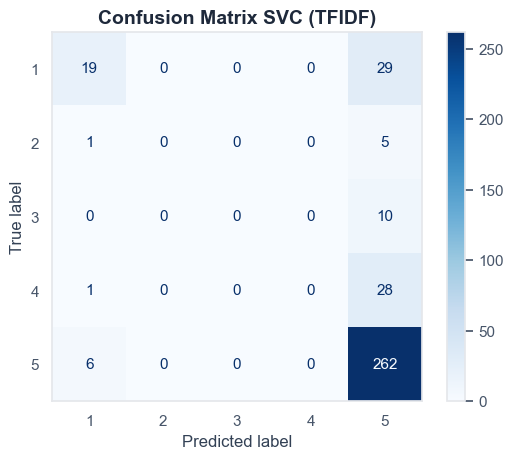

In [1637]:
cm_svc_tfidf = confusion_matrix(y_test, y_pred_best_svc_tfidf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_tfidf, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix SVC (TFIDF)")
plt.show()

Pada GridSearch model SVC dengan TFIDF, parameter terbaik dari hasil GridSearch adalah C=1 dan Kernelnya Linear. Hasil yang didapatkan tidak terlalu banyak berubah dengan model mentah sebelumnya. Namun, terlihat bahwa ada peningkatan performa pada f1-score kelas 1, di mana model mulai lebih berani memprediksi kelas 1 dengan lebih akurat.

##### E.1.3.2. Using Word2Vec

In [1638]:
svc_model_ht_w2c = SVC(probability=True)
grid_search_svc_w2v = GridSearchCV(estimator=svc_model_ht_w2c, param_grid=param_grid_svc, cv=5, n_jobs=-1)
grid_search_svc_w2v.fit(X_train_w2v, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(probability=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displa

In [1639]:
best_model_svc_w2v = grid_search_svc_w2v.best_estimator_
y_pred_best_svc_w2v = best_model_svc_w2v.predict(X_test_w2v)

In [1640]:
y_prob_best_svc_w2v = best_model_svc_w2v.predict_proba(X_test_w2v)
auc_best_svc_w2v = roc_auc_score(y_test, y_prob_best_svc_w2v, multi_class='ovr')

In [1641]:
print("Classification Report Using Best SVC (Word2Vec):")
print(classification_report(y_test, y_pred_best_svc_w2v))
print("AUC= ", auc_best_svc_w2v)

Classification Report Using Best SVC (Word2Vec):
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.74      1.00      0.85       268

    accuracy                           0.74       361
   macro avg       0.15      0.20      0.17       361
weighted avg       0.55      0.74      0.63       361

AUC=  0.5757903540627737


c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

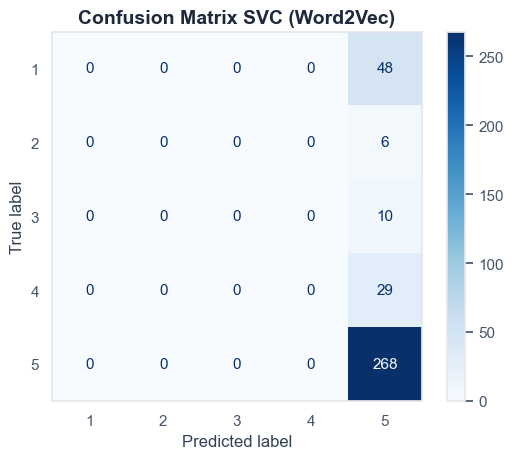

In [1642]:
cm_svc_w2v = confusion_matrix(y_test, y_pred_best_svc_w2v)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_w2v, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix SVC (Word2Vec)")
plt.show()

Selain itu, dengan menggunakan Grid Search dengan SVC Word2Vec, Parameter terbaik adalah C=1000 dengan kernel 'rbf'. Tidak terjadi perubahan yang signifikan dan mayoritas model hanya berani untuk menebak dan memprediksi kelas mayoritas yaitu kelas 5. Dari hasil ini, dapat dilihat bahwa SVC dengan pendekatan representasi TFIDF memiliki hasil yang lebih baik dibandingkan pendekatan dengan Word2Vec.

### E.2. Random Forest

Model kedua yang saya gunakan adalah Random Forest Model. Random forest merupakan model yang lebih robust dan tahan terhadap data yang memiliki banyak noise. Dikarenakan Random Forest memiliki mekanisme Decision Tree yang digabungkan (ensemble) sehingga mampu untuk mengatasi fitur noise yang dapat menipu model.

#### E.2.1. Using TFIDF

In [1643]:
ranfor_model_tfidf = RandomForestClassifier(n_estimators=100, random_state=42)
ranfor_model_tfidf.fit(X_train_tfidf, y_train)
y_pred_ranfor_tfidf = ranfor_model_tfidf.predict(X_test_tfidf)

In [1644]:
print("Classification Report Using Random Forest (TFIDF):")
print(classification_report(y_test, y_pred_ranfor_tfidf))

Classification Report Using Random Forest (TFIDF):
              precision    recall  f1-score   support

           1       0.64      0.38      0.47        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.78      0.96      0.86       268

    accuracy                           0.76       361
   macro avg       0.28      0.27      0.27       361
weighted avg       0.67      0.76      0.70       361



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

Pertama, random forest model yang saya gunakan adalah model mentah tanpa tuning parameter. Dari pendekatan TFIDF dan model Random Forest mentah, didapatkan hasil yang hampir mirip dengan hasil pada model SVC yaitu model hanya berani untuk memprediksi kelas 1 dan kelas 5, dan tidak mampu memprediksi kelas lainnya sama sekali.

#### E.2.2. Using Word2Vec

In [1645]:
ranfor_model_w2v = RandomForestClassifier(n_estimators=100, random_state=42)
ranfor_model_w2v.fit(X_train_w2v, y_train)
y_pred_ranfor_w2v = ranfor_model_w2v.predict(X_test_w2v)

In [1646]:
print("Classification Report Using Random Forest (Word2Vec):")
print(classification_report(y_test, y_pred_ranfor_w2v))

Classification Report Using Random Forest (Word2Vec):
              precision    recall  f1-score   support

           1       0.86      0.12      0.22        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.75      0.99      0.86       268

    accuracy                           0.75       361
   macro avg       0.32      0.22      0.21       361
weighted avg       0.67      0.75      0.66       361



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

Selanjutnya dengan menggunakan model yang sama, yaitu Random Forest mentah didapatkan hasil yang serupa dengan pendekatan TFIDF sebelumnya. Yaitu model hanya memprediksi kelas 5 dan kelas 1, dan tidak mampu memprediksi kelas lainnya sama sekali.

#### E.2.3. Hyperparameter Tuning

In [1647]:
param_grid_ranfor = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

Selanjutnya saya akan melakukan Hyperparameter Tuning dengan GridSearch dan melakukan tuning pada beberapa hyperparameter pada model Random Forest. Berikut ini adalah beberapa parameter yang akan di tuning pada GridSearch:
1. n_estimators --> Merupakan berapa jumlah tree yang ada di dalam forest. Dengan menambah n_estimators maka akan menambah performa dan komputasi model. Namun dapat memperberat perhitungan
2. max_depth --> mengontrol maximal kedalaman dari tree
3. min_samples_split --> nilai minimum samples untuk memecah internal node
4. min_samples_leaf --> menentukan jumlah minimum data yang harus ada di setiap leaf node atau daun

##### E.2.3.1. Using TFIDF

In [1648]:
ranfor_model_ht_tfidf = RandomForestClassifier(random_state=42)
grid_search_ranfor_tfidf = GridSearchCV(estimator=ranfor_model_ht_tfidf, param_grid=param_grid_ranfor, cv=5, n_jobs=-1)
grid_search_ranfor_tfidf.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter ca

In [1649]:
best_model_ranfor_tfidf = grid_search_ranfor_tfidf.best_estimator_
y_pred_best_ranfor_tfidf = best_model_ranfor_tfidf.predict(X_test_tfidf)

In [1650]:
y_prob_best_ranfor_tfidf = best_model_ranfor_tfidf.predict_proba(X_test_tfidf)
auc_best_ranfor_tfidf = roc_auc_score(y_test, y_prob_best_ranfor_tfidf, multi_class='ovr')

In [1651]:
print("Classification Report Using Best Random Forest (TFIDF):")
print(classification_report(y_test, y_pred_best_ranfor_tfidf))
print("AUC= ", auc_best_ranfor_tfidf)

Classification Report Using Best Random Forest (TFIDF):
              precision    recall  f1-score   support

           1       0.69      0.38      0.49        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.78      0.97      0.87       268

    accuracy                           0.77       361
   macro avg       0.29      0.27      0.27       361
weighted avg       0.67      0.77      0.71       361

AUC=  0.6793769803030325


c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

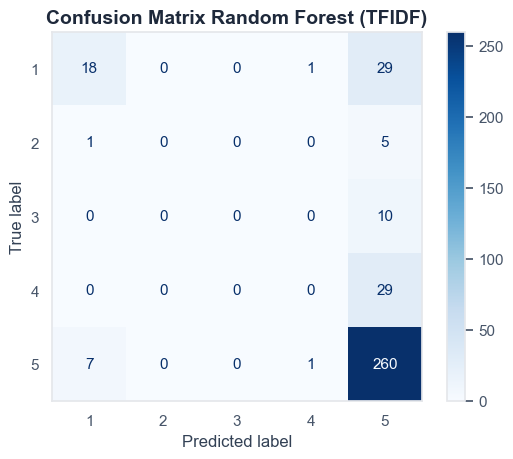

In [1652]:
cm_rf_tfidf = confusion_matrix(y_test, y_pred_best_ranfor_tfidf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_tfidf, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Random Forest (TFIDF)")
plt.show()

Dengan menggunakan GridSearch pada RandomForest model dengan pendekatan TFIDF, didapat hasil yang tidak jauh berbeda dengan model SVC dan model RandomForest mentah di awal. Parameter terbaiknya adalah min_sample_leaf=2, min_samples_split=5, dan n_estimators=300. Model masih cenderung untuk memprediksi kelas mayoritas yaitu kelas 5.

##### E.2.3.2. Using Word2Vec

In [1653]:
ranfor_model_ht_w2v = RandomForestClassifier(random_state=42)
grid_search_ranfor_w2v = GridSearchCV(estimator=ranfor_model_ht_w2v, param_grid=param_grid_ranfor, cv=5, n_jobs=-1)
grid_search_ranfor_w2v.fit(X_train_w2v, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter ca

In [1654]:
best_model_ranfor_w2v = grid_search_ranfor_w2v.best_estimator_
y_pred_best_ranfor_w2v = best_model_ranfor_w2v.predict(X_test_w2v)

In [1655]:
y_prob_best_ranfor_w2v = best_model_ranfor_w2v.predict_proba(X_test_w2v)
auc_best_ranfor_w2v = roc_auc_score(y_test, y_prob_best_ranfor_w2v, multi_class='ovr')

In [1656]:
print("Classification Report Using Best Random Forest (Word2Vec):")
print(classification_report(y_test, y_pred_best_ranfor_w2v))
print("AUC= ", auc_best_ranfor_w2v)

Classification Report Using Best Random Forest (Word2Vec):
              precision    recall  f1-score   support

           1       0.75      0.12      0.21        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.75      0.99      0.86       268

    accuracy                           0.75       361
   macro avg       0.30      0.22      0.21       361
weighted avg       0.66      0.75      0.66       361

AUC=  0.6092124425071208


c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

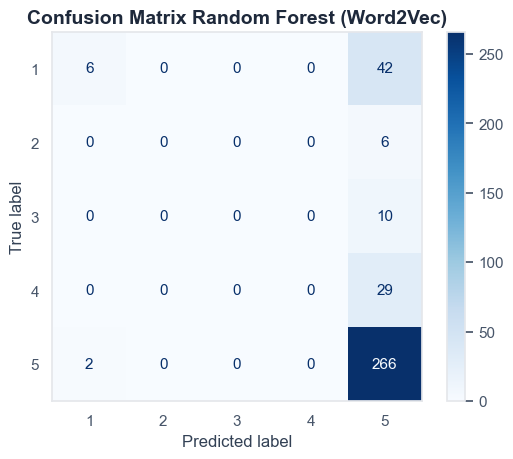

In [1657]:
cm_rf_w2v = confusion_matrix(y_test, y_pred_best_ranfor_w2v)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_w2v, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Random Forest (Word2Vec)")
plt.show()

Dengan pendekatan text representation Word2Vec, didapati hasil yang sama dengan model sebelumnya. Best parameter yang didapat adalah, max_depth=20, min_samples_leaf=2, dan min_samples_split=5. Walaupun terlihat mirip, namun model ini memiliki performa untuk memprediksi kelas 1 yang lebih rendah dibandingkan model-model sebelumnya.

## F. Deep Learning Classification

Anda tidak puas hanya menggunakan machine learning sebagai metode klasifikasi,
anda ingin mencoba menggunakan metode deep learning, maka anda menggunakan suatu metode deep learning
yang anda pilih sendiri dengan metode text representation yang digunakan adalah pendekatan dengan vectornya
direpresentasikan oleh kata disekitarnya yang ditraining dengan model ANN; tentu saja anda juga perlu melakukan
tuning hyperparameter minimal 2 hyperparameters.

Setelah melakukan klasifikasi menggunakan pendekatan Machine Learning, hasil yang ditunjukkan hanya cenderung kepada kelas dominan saja yaitu kelas 5. Maka dari itu, saya melakukan metode dengan pendekatan Deep Learning. Dengan harapan bahwa pendekatan Deep Learning dapat mengatasi permasalahan pada Machine Learning yang kurang mampu menangkap fitur kompleks dan cenderung hanya pada satu kelas saja.

### F.1. LSTM

Salah satu algoritma atau model Deep Learning yang umum digunakan untuk klasifikasi teks adalah LSTM atau Long Short Term Memory. LSTM merupakan algoritma neural network yang telah diupgrade dari pendekatan sebelumnya yaitu RNN (Reccurent Neural Network). LSTM berbeda dari machine learning model yang telah dibuat sebelumnya. LSTM mampu melihat dan membaca teks secara sequential, kata demi kata dan dapat mengingat kata yang telah dilihat sebelumnya.

!['LSTM'](images/lstm.png)

Berikut ini adalah arsitektur dari LSTM dan cara kerja sistem arsitektur dari LSTM:
1. forget gate --> gate yang mengatur informasi apa yang akan diteruskan dengan membuang informasi lama
2. Input gate --> input gate adalah pintu masuk informasi baru yang akan dibaca dan disimpan
3. output gate --> output gate adalah pintu keluar informasi, gate ini akan mengatur informasi yang keluar sebagai hidden state

In [1658]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.initializers import Constant

In [1659]:
model_dl_w2v = Sequential([
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=100,
        embeddings_initializer=Constant(embedding_matrix),
        input_length=max_len,
        trainable=True,
        mask_zero=True
    ),
    layers.LSTM(64, dropout=0.2),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')
])

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model LSTM terdiri dari:
1. embedding layer --> Ini merupakan hasil embedding matrix yang tadi diinput dengan hasil Word2Vec, dengan adanya embedding layer maka LSTM model sudah memiliki pre-trained weight
2. LSTM layer --> merupakan layer utama model 
3. BatchNormalization --> layer yang menstabilkan output memori dari LSTM dengan menormalkan aktivasi neuron pada setiap mini batch, lalu melakukan normalisasi.
4. Dense (output layer) --> merupakan layer output 

In [1660]:
model_dl_w2v.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dl_w2v.build(input_shape=(None, max_len))

In [1661]:
model_dl_w2v.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 112, 100)       │       236,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,421 (1.07 MB)

 Trainable params: 279,293 (1.07 MB)

 Non-trainable params: 128 (512.00 B)

In [1662]:
label_mapping = {
    1: 0,
    2: 1,
    3: 2,
    4: 3,
    5: 4
}

y_train_dl = y_train.map(label_mapping)
y_test_dl = y_test.map(label_mapping)

In [1663]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [1664]:
history_dl_w2v = model_dl_w2v.fit(
    X_train_padding, y_train_dl,
    validation_split=0.2,
    epochs=15,
    batch_size=32,
    # callbacks=[early_stop],
)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.4948 - loss: 1.5572 - val_accuracy: 0.7674 - val_loss: 1.3395
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.6727 - loss: 1.2046 - val_accuracy: 0.7674 - val_loss: 1.1570
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.7908 - loss: 0.8789 - val_accuracy: 0.7674 - val_loss: 0.9769
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.8368 - loss: 0.6260 - val_accuracy: 0.7674 - val_loss: 0.9068
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.8837 - loss: 0.4658 - val_accuracy: 0.7674 - val_loss: 0.8454
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.9010 - loss: 0.3862 - val_accuracy: 0.7882 - val_loss: 0.7872
Epoch 7/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.9089 - loss: 0.3661 - val_accuracy: 0.7708 - val_loss: 0.7658
Epoch 8/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.9149 - loss: 0.3222 - val_accuracy: 0.7847 - v

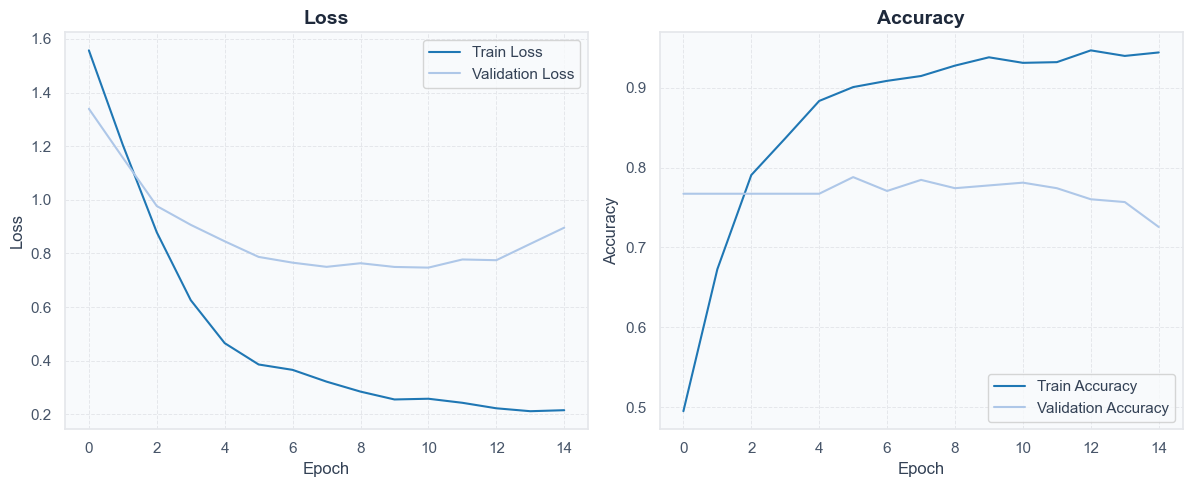

In [1665]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history_dl_w2v.history['loss'], label='Train Loss')
plt.plot(history_dl_w2v.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history_dl_w2v.history['accuracy'], label='Train Accuracy')
plt.plot(history_dl_w2v.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Setelah melakukan 15 Epochs training, didapatkan grafik loss dan accuracy sebagai berikut:
1. Loss plot --> setelah 15 epochs, didapati bahwa training loss terus menurun dan menunjukkan bahwa model belajar dengan baik selama training. Namun, untuk validation loss, terlihat bahwa validation loss hanya turun sampai 0.8 pada epoch ke 4 dan mengalami stuck (konstan) sampai epoch 15. hal ini menunjukkan adanya indikasi overfitting selama proses training dilakukan
2. Accuracy plot --> setelah 15 epochs, didapati bahwa akurasi model pada training terus meningkat seiring bertambahnya epoch. Namun akurasi mengalami stuck dan konstan dari awal epoch sampai akhir epoch 15. Hal ini menunjukkan overfitting pada model

In [1666]:
# model_dl_w2v_import = tf.keras.models.load_model('./model/model_dl_w2v.keras')

In [1667]:
y_pred_dl_w2v = model_dl_w2v.predict(X_test_padding)
y_pred_dl_w2v_classes = np.argmax(y_pred_dl_w2v, axis=1) + 1

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


In [1668]:
auc_dl_w2v = roc_auc_score(y_test, y_pred_dl_w2v, multi_class='ovr')

In [1669]:
print("Classification Report Using LSTM (Word2Vec):")
print(classification_report(y_test, y_pred_dl_w2v_classes))
print("AUC= ", auc_dl_w2v)

Classification Report Using LSTM (Word2Vec):
              precision    recall  f1-score   support

           1       0.40      0.38      0.39        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.08      0.03      0.05        29
           5       0.82      0.90      0.86       268

    accuracy                           0.72       361
   macro avg       0.26      0.26      0.26       361
weighted avg       0.67      0.72      0.69       361

AUC=  0.6672339012378959


<Figure size 600x600 with 0 Axes>

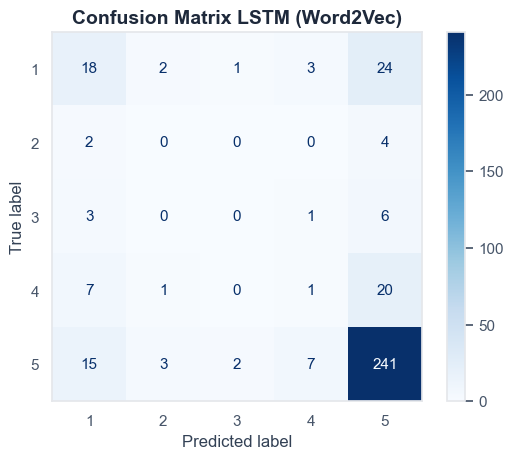

In [1670]:
cm_dl_w2v = confusion_matrix(y_test, y_pred_dl_w2v_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dl_w2v, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix LSTM (Word2Vec)")
plt.show()

Berdasarkan hasil classification report dan Confusion matrix di atas, didapati bahwa model Deep Learning juga mengalami permasalahan yang sama yaitu model hanya mampu memprediksi kelas 5 dan kelas 1. Berdasarkan analisis saya, ini menandakan bahwa permasalahan utama pada klasifikasi ini adalah pada kualitas data scraping yang dilakukan.

In [1671]:
# model_dl_w2v.save('model_dl_w2v.keras')

### F.2. Hyperparameter Tuning

In [1672]:
import keras_tuner as kt

In [1673]:
from torch import dropout


def lstm_builder(hp):
    model = Sequential()
    model.add(layers.Embedding(
        input_dim=vocab_size,
        output_dim=100,
        embeddings_initializer=Constant(embedding_matrix),
        input_length=max_len,
        trainable=True,
        mask_zero=True
    ))

    hp_units = hp.Int('units', min_value=32, max_value=128, step=32)
    dropout_rate = hp.Float('dropout', min_value=0.1, max_value=0.5, step=0.1)
    model.add(layers.LSTM(hp_units, dropout=dropout_rate))
    model.add(layers.BatchNormalization())
    model.add(layers.Dense(5, activation='softmax'))
    
    hp_lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

Kemudian, pada model Deep Learning LSTM, dilakukan juga hyperparameter tuning pada jumlah neuron LSTM, dropout rate dan learning rate. 

In [1674]:
tuner = kt.GridSearch(
    hypermodel=lstm_builder,
    objective='val_loss',
    max_trials=20,
    executions_per_trial=1,
    directory='lstm_tuning',
    project_name='lstm_w2v'
)

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [1675]:
tuner.search(
    X_train_padding, y_train_dl,
    validation_split=0.2,
    epochs=15,
    batch_size=32,
    verbose=1,
    # callbacks=[early_stop],
)

Trial 20 Complete [00h 00m 36s]
val_loss: 0.7465128302574158

Best val_loss So Far: 0.726144552230835
Total elapsed time: 00h 09m 52s


Setelah melakukan GridSearch menggunakan Keras Tuner, didapat bahwa best validation loss terbaik berada pada 0.73.

In [1676]:
best = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best LSTM Units: ", best.get('units'))
print("Best Dropout Rate: ", best.get('dropout'))
print("Best Learning Rate: ", best.get('learning_rate'))

Best LSTM Units:  32
Best Dropout Rate:  0.5
Best Learning Rate:  0.001


Di atas ini merupakan settingan atau parameter terbaik dari hasil GridSearch model LSTM.

In [1677]:
best_model_dl_w2v = tuner.get_best_models(num_models=1)[0]

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [1678]:
y_pred_dl_w2v_best = best_model_dl_w2v.predict(X_test_padding)
y_pred_dl_w2v_best_classes = np.argmax(y_pred_dl_w2v_best, axis=1) + 1

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


In [1679]:
auc_dl_w2v_best = roc_auc_score(y_test, y_pred_dl_w2v_best, multi_class='ovr')

In [1680]:
print("Classification Report Using Best LSTM (Word2Vec):")
print(classification_report(y_test, y_pred_dl_w2v_best_classes))
print("AUC= ", auc_dl_w2v_best)

Classification Report Using Best LSTM (Word2Vec):
              precision    recall  f1-score   support

           1       0.50      0.12      0.20        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        29
           5       0.76      0.99      0.86       268

    accuracy                           0.75       361
   macro avg       0.25      0.22      0.21       361
weighted avg       0.63      0.75      0.66       361

AUC=  0.6612964190704724


c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

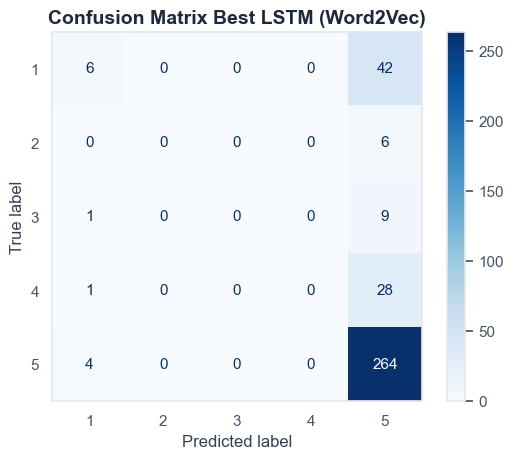

In [1681]:
cm_dl_w2v_best = confusion_matrix(y_test, y_pred_dl_w2v_best_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dl_w2v_best, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Best LSTM (Word2Vec)")
plt.show()

Ternyata, setelah melakukan GridSearch, hasil yang didapat cukup buruk dan kurang memuaskan. Model hanya memprediksi kelas 5 saja dan tidak dapat memprediksi kelas lain. Hasil model ini menunjukkan performa yang kurang baik dan menunjukkan indikasi bahwa terjadi problem pada dataset, distribusi kelas, atau kualitas teks data yang menyebabkan model ML dan DL mengalami kesulitan untuk membedakan satu kelas dengan kelas lainnya.

## G. Handle The Imbalance Data

Anda mendapati ternyata data anda imbalance, sehingga anda penasaran, apakah
jika kondisi imbalance data ini dihandle, akan ada perubahan pada perfomance atau tidak, sehingga anda
melakukan treatment terhadap data imbalance dan melakukan training kembali dan melakukan evaluasi terhadap
model dengan kondisi data baru. Anda membandingkan evaluasi performancenya dan mendapatkan kesimpulan,
model mana yang terbaik

Dari proses eksplorasi data, didapati bahwa distribusi kelas pada dataset mengalami imbalance yang cukup parah. Imbalance data dapat sangat mempengaruhi performa model dikarenakan model ML atau DL didesain untuk mendapat akurasi tinggi, dan ketika model berhasil memprediksi benar secara terus menerus pada kelas mayoritas, maka model akan cenderung untuk terus menebak kelas tersebut.

### G.1. Class Weight

Salah satu metode yang dapat diterapkan adalah Class Weighting. Saya memilih metode ini dikarenakan Class Weighting merupakan salah satu metode yang terbaik untuk kasus dengan dataset kecil dan imbalance yang cukup parah. Dikarenakan Class Weighting bekerja dengan memberikan penalti yang lebih besar pada kelas yang lebih kecil. Apabila model salah memprediksi kelas minoritas, maka penalti yang diberikan akan lebih besar sehingga model akan lebih memperhitungkan dan memperhatikan kelas minoritas.

In [1682]:
from sklearn.utils import class_weight

In [1683]:
weight_ml = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_ml = dict(zip(np.unique(y_train), weight_ml))
class_weight_ml

{np.int64(1): np.float64(1.4545454545454546),
 np.int64(2): np.float64(9.6),
 np.int64(3): np.float64(6.6976744186046515),
 np.int64(4): np.float64(3.4698795180722892),
 np.int64(5): np.float64(0.26519337016574585)}

In [1684]:
weight_dl = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_dl),
    y=y_train_dl
)
class_weight_dl = dict(zip(np.unique(y_train_dl), weight_dl))
class_weight_dl

{np.int64(0): np.float64(1.4545454545454546),
 np.int64(1): np.float64(9.6),
 np.int64(2): np.float64(6.6976744186046515),
 np.int64(3): np.float64(3.4698795180722892),
 np.int64(4): np.float64(0.26519337016574585)}

#### G.1.1. SVC

##### G.1.1.1. TFIDF

In [1685]:
svc_model_ht_tfidf_cw = SVC(class_weight=class_weight_ml, probability=True)
grid_search_svc_tfidf_cw = GridSearchCV(estimator=svc_model_ht_tfidf_cw, param_grid=param_grid_svc, cv=5, n_jobs=-1)
grid_search_svc_tfidf_cw.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(class_wei...bability=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is al

In [1686]:
best_model_svc_tfidf_cw = grid_search_svc_tfidf_cw.best_estimator_
y_pred_best_svc_tfidf_cw = best_model_svc_tfidf_cw.predict(X_test_tfidf)

In [1687]:
y_prob_best_svc_tfidf_cw = best_model_svc_tfidf_cw.predict_proba(X_test_tfidf)
auc_best_svc_tfidf_cw = roc_auc_score(y_test, y_prob_best_svc_tfidf_cw, multi_class='ovr')

In [1688]:
print("Classification Report Using Best SVC with CW (TFIDF):")
print(classification_report(y_test, y_pred_best_svc_tfidf_cw))
print("AUC= ", auc_best_svc_tfidf_cw)

Classification Report Using Best SVC with CW (TFIDF):
              precision    recall  f1-score   support

           1       0.50      0.65      0.56        48
           2       0.00      0.00      0.00         6
           3       0.07      0.10      0.08        10
           4       0.11      0.24      0.15        29
           5       0.82      0.66      0.73       268

    accuracy                           0.60       361
   macro avg       0.30      0.33      0.31       361
weighted avg       0.68      0.60      0.63       361

AUC=  0.6788800531956259


<Figure size 600x600 with 0 Axes>

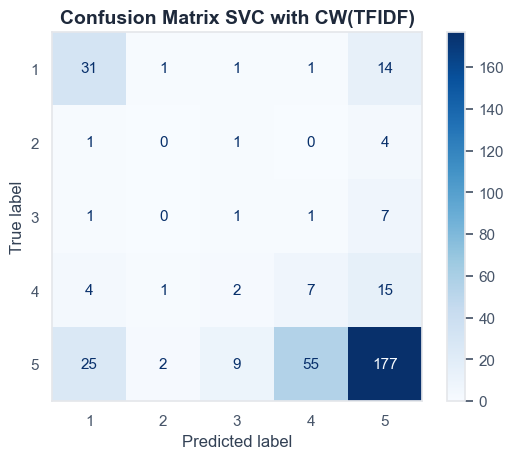

In [1689]:
cm_svc_tfidf_cw = confusion_matrix(y_test, y_pred_best_svc_tfidf_cw)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_tfidf_cw, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix SVC with CW(TFIDF)")
plt.show()

Setelah menerapkan Class Weight pada SVC dengan TFIDF, didapati bahwa model sudah lebih berani/mampu untuk memprediksi kelas lain selain kelas mayoritas (kelas 5). Walaupun akurasi terlihat menurun, namun terlihat model mulai berani memprediksi kelas lain, dan f1-score pada kelas 1 mulai meningkat.

##### G.1.1.2. Word2Vec

In [1690]:
svc_model_ht_w2c_cw = SVC(class_weight=class_weight_ml, probability=True)
grid_search_svc_w2v_cw = GridSearchCV(estimator=svc_model_ht_w2c_cw, param_grid=param_grid_svc, cv=5, n_jobs=-1)
grid_search_svc_w2v_cw.fit(X_train_w2v, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(class_wei...bability=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is al

In [1691]:
best_model_svc_w2v_cw = grid_search_svc_w2v_cw.best_estimator_
y_pred_best_svc_w2v_cw = best_model_svc_w2v_cw.predict(X_test_w2v)

In [1692]:
y_prob_best_svc_w2v_cw = best_model_svc_w2v_cw.predict_proba(X_test_w2v)
auc_best_svc_w2v_cw = roc_auc_score(y_test, y_prob_best_svc_w2v_cw, multi_class='ovr')

In [1693]:
print("Classification Report Using Best SVC with CW (Word2Vec):")
print(classification_report(y_test, y_pred_best_svc_w2v_cw))
print("AUC= ", auc_best_svc_w2v_cw)

Classification Report Using Best SVC with CW (Word2Vec):
              precision    recall  f1-score   support

           1       0.35      0.42      0.38        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.17      0.31      0.22        29
           5       0.84      0.43      0.57       268

    accuracy                           0.40       361
   macro avg       0.27      0.23      0.23       361
weighted avg       0.69      0.40      0.49       361

AUC=  0.6375047649802126


<Figure size 600x600 with 0 Axes>

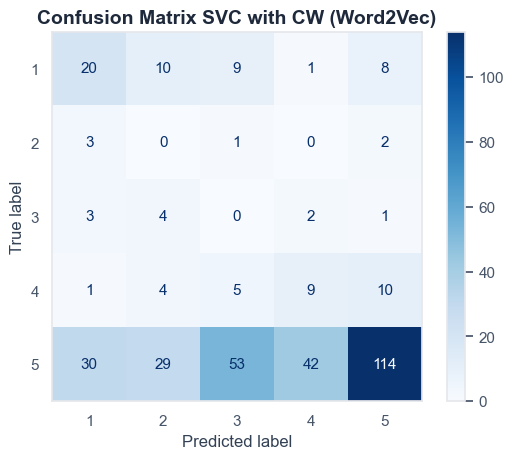

In [1694]:
cm_svc_w2v_cw = confusion_matrix(y_test, y_pred_best_svc_w2v_cw)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_w2v_cw, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix SVC with CW (Word2Vec)")
plt.show()

Dengan menggunakan SVC dan Word2Vec, hasil menunjukkan prediksi yang lebih menyebar lagi dan tersebar pada setiap kelas. Namun menurut analisis saya, terlihat bahwa model mengalami penalti besar pada kelas minoritas, sehingga model jadi mulai memperhatikan kelas minoritas lain. Namun dikarenakan data test sedikit, hasil performa juga kurang dapat dilihat dengan baik

#### G.1.2. Random Forest

##### G.1.2.1. TFIDF

In [1695]:
ranfor_model_ht_tfidf_cw = RandomForestClassifier(random_state=42, class_weight=class_weight_ml)
grid_search_ranfor_tfidf_cw = GridSearchCV(estimator=ranfor_model_ht_tfidf_cw, param_grid=param_grid_ranfor, cv=5, n_jobs=-1)
grid_search_ranfor_tfidf_cw.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter ca

In [1696]:
best_model_ranfor_tfidf_cw = grid_search_ranfor_tfidf_cw.best_estimator_
y_pred_best_ranfor_tfidf_cw = best_model_ranfor_tfidf_cw.predict(X_test_tfidf)

In [1697]:
y_prob_best_ranfor_tfidf_cw = best_model_ranfor_tfidf_cw.predict_proba(X_test_tfidf)
auc_best_ranfor_tfidf_cw = roc_auc_score(y_test, y_prob_best_ranfor_tfidf_cw, multi_class='ovr')

In [1698]:
print("Classification Report Using Best Random Forest with CW(TFIDF):")
print(classification_report(y_test, y_pred_best_ranfor_tfidf_cw))
print("AUC= ", auc_best_ranfor_tfidf_cw)

Classification Report Using Best Random Forest with CW(TFIDF):
              precision    recall  f1-score   support

           1       0.60      0.50      0.55        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.11      0.14      0.12        29
           5       0.78      0.83      0.81       268

    accuracy                           0.69       361
   macro avg       0.30      0.29      0.30       361
weighted avg       0.67      0.69      0.68       361

AUC=  0.6112024194856797


<Figure size 600x600 with 0 Axes>

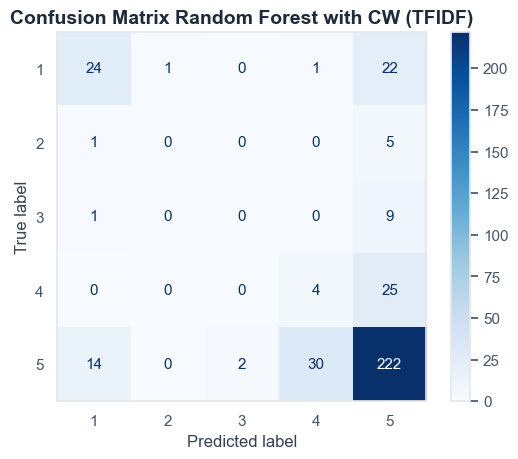

In [1699]:
cm_rf_tfidf_cw = confusion_matrix(y_test, y_pred_best_ranfor_tfidf_cw)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_tfidf_cw, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Random Forest with CW (TFIDF)")
plt.show()

Dengan menggunakan Random Forest dan TFIDF, didapati hasil yang serupa dengan model sebelumnya, dengan model cenderung memprediksi kelas 1 dan kelas 5. Model juga dapat memprediksi kelas 4, namun hasilnya masih kurang akurat. Hal ini dikarenakan karakteristik data kelas 4 dan 5 sangatlah mirip sehingga model masih kesulitan membedakan kedua kelas tersebut.

##### G.1.2.2. Word2Vec

In [1700]:
ranfor_model_ht_w2v_cw = RandomForestClassifier(random_state=42, class_weight=class_weight_ml)
grid_search_ranfor_w2v_cw = GridSearchCV(estimator=ranfor_model_ht_w2v_cw, param_grid=param_grid_ranfor, cv=5, n_jobs=-1)
grid_search_ranfor_w2v_cw.fit(X_train_w2v, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter ca

In [1701]:
best_model_ranfor_w2v_cw = grid_search_ranfor_w2v_cw.best_estimator_
y_pred_best_ranfor_w2v_cw = best_model_ranfor_w2v_cw.predict(X_test_w2v)

In [1702]:
y_prob_best_ranfor_w2v_cw = best_model_ranfor_w2v_cw.predict_proba(X_test_w2v)
auc_best_ranfor_w2v_cw = roc_auc_score(y_test, y_prob_best_ranfor_w2v_cw, multi_class='ovr')

In [1703]:
print("Classification Report Using Best Random Forest with CW (Word2Vec):")
print(classification_report(y_test, y_pred_best_ranfor_w2v_cw))
print("AUC= ", auc_best_ranfor_w2v_cw)

Classification Report Using Best Random Forest with CW (Word2Vec):
              precision    recall  f1-score   support

           1       0.44      0.15      0.22        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.07      0.03      0.05        29
           5       0.74      0.81      0.77       268

    accuracy                           0.62       361
   macro avg       0.25      0.20      0.21       361
weighted avg       0.61      0.62      0.61       361

AUC=  0.5762633334579734


<Figure size 600x600 with 0 Axes>

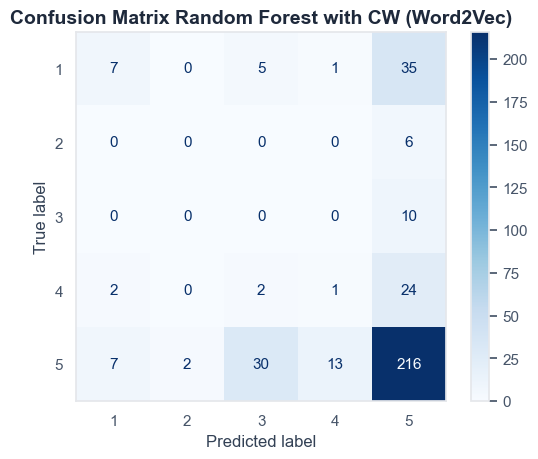

In [1704]:
cm_rf_w2v_cw = confusion_matrix(y_test, y_pred_best_ranfor_w2v_cw)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_w2v_cw, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Random Forest with CW (Word2Vec)")
plt.show()

Dengan menggunakan Random Forest dan Word2Vec, didapati hasil yang kurang baik dan kembali seperti model sebelum dilakukan tuning dan class weighting. Model hanya memprediksi kelas mayoritas dan tidak mampu memprediksi kelas lain yang minoritas.

#### G.1.3. LSTM

In [1705]:
model_dl_w2v_cw = Sequential([
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=100,
        embeddings_initializer=Constant(embedding_matrix),
        input_length=max_len,
        trainable=True,
        mask_zero=True 
    ),
    layers.LSTM(32, dropout=0.3), 
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')
])

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [1706]:
model_dl_w2v_cw.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dl_w2v_cw.build(input_shape=(None, max_len))

In [1707]:
model_dl_w2v_cw.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 112, 100)       │       236,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        17,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 253,917 (991.86 KB)

 Trainable params: 253,853 (991.61 KB)

 Non-trainable params: 64 (256.00 B)

In [1708]:
history_dl_w2v_cw = model_dl_w2v_cw.fit(
    X_train_padding, y_train_dl,
    validation_split=0.2,
    epochs=15,
    batch_size=32, 
    # callbacks=[early_stop],
    class_weight=class_weight_dl,
)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.2370 - loss: 1.9132 - val_accuracy: 0.3368 - val_loss: 1.5914
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.3333 - loss: 1.5840 - val_accuracy: 0.6007 - val_loss: 1.5204
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.3828 - loss: 1.3995 - val_accuracy: 0.5243 - val_loss: 1.5199
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.4280 - loss: 1.2583 - val_accuracy: 0.6285 - val_loss: 1.4868
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.4792 - loss: 1.0236 - val_accuracy: 0.7222 - val_loss: 1.3846
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5130 - loss: 0.8468 - val_accuracy: 0.7465 - val_loss: 1.2715
Epoch 7/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5495 - loss: 0.7091 - val_accuracy: 0.7674 - val_loss: 1.2370
Epoch 8/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5920 - loss: 0.6435 - val_accuracy: 0.7153 - v

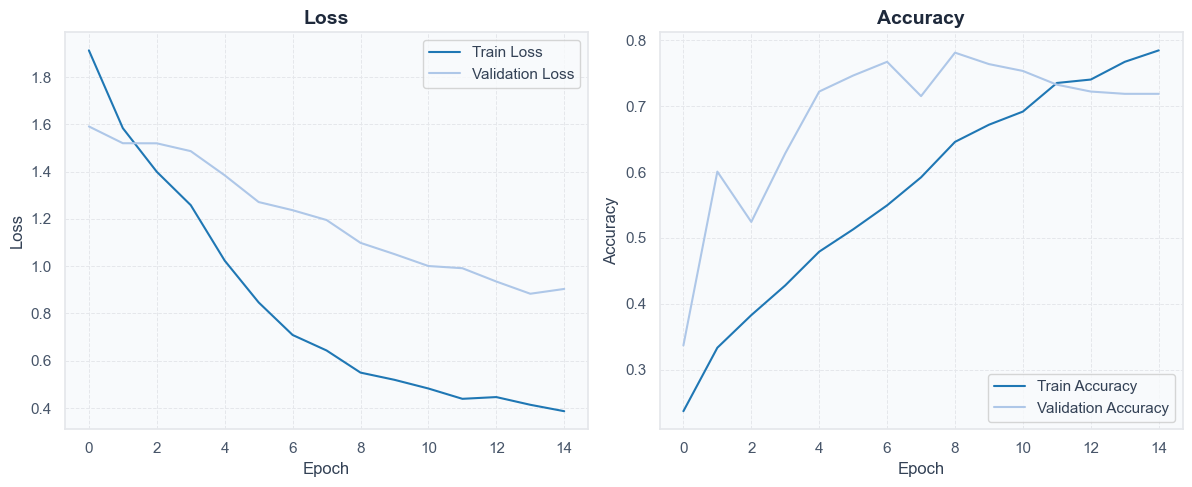

In [1709]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history_dl_w2v_cw.history['loss'], label='Train Loss')
plt.plot(history_dl_w2v_cw.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history_dl_w2v_cw.history['accuracy'], label='Train Accuracy')
plt.plot(history_dl_w2v_cw.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Berdasarkan training 15 epochs dengan parameter dari best parameter sebelumnya:
1. Loss plot --> Di dapati training loss dan validation loss secara bertahap turun namun validation loss tetap berada di atas training loss sehingga menunjukkann indikasi overfitting ketika training
2. Accuracy plot --> selama training, validation accuracy dengan training accuracy meningkat secara bertahap dengan validation accuracy berada di atas training accuracy

In [1710]:
y_pred_dl_w2v_cw = model_dl_w2v_cw.predict(X_test_padding)
y_pred_dl_w2v_cw_classes = np.argmax(y_pred_dl_w2v_cw, axis=1) + 1

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [1711]:
auc_dl_w2v_cw = roc_auc_score(y_test, y_pred_dl_w2v_cw, multi_class='ovr')

In [1712]:
print("Classification Report Using LSTM (Word2Vec):")
print(classification_report(y_test, y_pred_dl_w2v_cw_classes))
print("AUC= ", auc_dl_w2v_cw)

Classification Report Using LSTM (Word2Vec):
              precision    recall  f1-score   support

           1       0.39      0.33      0.36        48
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        10
           4       0.05      0.03      0.04        29
           5       0.80      0.85      0.83       268

    accuracy                           0.68       361
   macro avg       0.25      0.24      0.25       361
weighted avg       0.65      0.68      0.67       361

AUC=  0.6031377307700958


<Figure size 600x600 with 0 Axes>

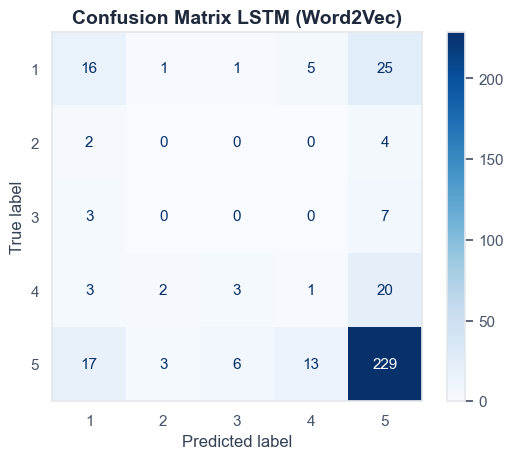

In [1713]:
cm_dl_w2v_cw = confusion_matrix(y_test, y_pred_dl_w2v_cw_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dl_w2v_cw, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix LSTM (Word2Vec)")
plt.show()

Hasil dari classification report dan confusion matrix menunjukkan hasil di mana model masih memprediksi kelas mayoritas. Namun hasil prediksi ada menunjukkan prediksi yang menyebar pada setiap kelas walaupun dengan hasil yang masih tidak akurat pada kelas minoritas.

## H. Conclusion

Berdasarkan project yang telah saya lakukan menggunakan data scraping review games dengan metode text representation TFIDF dan Word2Vec serta menggunakan algorithm Machine Learning dan pendekatan Deep Learning LSTM, saya mendapatkan kesimpulan sebagai berikut:
1. Data yang saya peroleh dari hasil scraping sejak awal menunjukkan kondisi data yang imbalance, hal ini cukup normal pada proses scraping data apalagi dengan sumber data review games. Menurut analisis saya, review games memiliki mayoritas rating di 1 dan 5 dikarenakan pengguna akan memberikan 5 jika menyukai dan 1 jika tidak menyukai. Pengguna akan lebih jarang memberikan bintang di tengah-tengah seperti 2,3,4.
2. Berdasarkan hasil dari EDA atau eksplorasi data, Didapatkan bahwa karakteristik kata pada setiap kelas memiliki karakteristik yang serupa sehingga kurang terlihat perbatasan antara satu kelas dengan lainnya. Misalkan seperti kelas 3,4, dan 5, yang menurut saya memiliki 80% kata yang mirip dan kelas 1-2 yang kurang menonjolkan kata-kata 'dislike' kepada game sehingga nantinya dapat menyulitkan model dalam membedakan dan memprediksi kelas.
3. Model Machine Learning kurang dapat mempelajari kelas minoritas, hal ini ditunjukkan dengan model yang cenderung selalu memprediksi kelas mayoritas seperti 5 dan 1. Dengan metode text representation TFIDF maupun Word2Vec menunjukkan performa yang serupa. Walaupun dengan menebak kelas mayoritas dapat memberikan akurasi yang tinggi, namun hal ini tidak menunjukkan performa yang baik dikarenakan pada prediksi rating atau sentiment analysis, rating yang rendah justru memiliki informasi yang kuat mengenai kelemahan maupun bug yang dimiliki oleh game. Sehingga memprediksi kelas kecil akan lebih penting dibandingkan memprediksi kelas mayoritas seperti 5 yang mayoritas hanya berisi pujian kepada game tanpa review yang jelas terhadap game.
4. Pendekatan Deep Learning juga menunjukkan hasil yang serupa dengan metode Machine Learning. DL yang sebelumnya diharapkan untuk dapat menangkap pola kompleks dari setiap kelas ternyata gagal dan menunjukkan performa yang kurang memuaskan. Walaupun terlihat bahwa loss menurun dan akurasi baik, namun hal ini tetap saja dikarenakan oleh model yang cenderung untuk terus menerus menebak kelas mayoritas
5. Metode handling imbalance data menggunakan Class Weight sedikit banyak membantu model agar dapat belajar dan memahami pola data pada setiap kelas. Namun menurut analisis saya, kemampuan model + class weight belum menunjukkan akurasi dan performa yang baik. Model berhasil memprediksi kelas lain hanya dikarenakan penalti yang besar sehingga akhirnya model mulai memperhatikan dan berani memprediksi kelas minoritas. Namun sebenarnya, model masih belum dapat menangkap dan membedakan satu kelas dengan kelas lainnya. Sehingga hasil prediksi masih dapat dikategorikan kurang baik
6. Saran yang dapat dilakukan untuk meningkatkan akurasi dan performa model adalah dengan menggunakan data yang lebih besar serta mengumpulkan data dengan kelas minoritas yang lebih banyak. Dengan menambah data dan menerapkan metode class weight, model akan lebih banyak belajar vocabulary lain dan mungkin akan menemukan karakteristik dan perbatasan antara satu kelas dengan kelas lainnya dengan lebih jelas. Sehingga model dapat memprediksi kelas dengan lebih akurat serta mampu membedakan setiap kelas dengan baik

## I. Referensi

https://www.kaggle.com/code/pierremegret/gensim-word2vec-tutorial <br>
https://www.geeksforgeeks.org/machine-learning/svm-hyperparameter-tuning-using-gridsearchcv-ml/ <br>
https://colab.research.google.com/drive/1Y6zsaWEHn7JZuo9qpb2MvaEbjHAYzeP3#scrollTo=duXm-XcVaPYK <br>
https://www.geeksforgeeks.org/machine-learning/random-forest-hyperparameter-tuning-in-python/ <br>
https://medium.com/@fraidoonomarzai99/word2vec-cbow-skip-gram-in-depth-88d9cc340a50 <br>
https://github.com/JoMingyu/google-play-scraper <br>
https://github.com/johanescedrick/emotion-analysis-bigru-distilbert <br>

## J. Video Link

Video Link: https://binusianorg-my.sharepoint.com/personal/johanes_wijaya002_binus_ac_id/_layouts/15/guestaccess.aspx?share=IQASpI-0q0jaRp7_u-BkObcnARoGdInYQA6yPAoUwHjuLps&nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=AvRhSD 